# CivicFlux — Infrastructure Measurement Anomaly Detection

**Notebook 05 · Version 1.0.0 · Historical benchmark + isolated injected fixtures**

An educational monitoring study, not equipment-failure diagnosis. This extension preserves the executed notebooks 01–04 and reuses the existing source canonicalizer. Models and tests run outside Jupyter through `src/civicflux/anomaly.py`. No municipal sensors, fault labels, coordinates or dispatch actions are invented.

## 01. Research objective and evidence boundaries

Flag an unusual current measurement or reporting condition at a source-qualified entity. The horizon is **contemporaneous detection**, after the current reading becomes available. A large score is not a calibrated fault probability. Environmental extremes, traffic growth, reporting delays and sensor malfunction can all produce unusual values; independent evidence is required to distinguish them.

Research questions: (1) Which temporal features are causally available? (2) How do rules, robust deviations and Isolation Forest differ? (3) Are alert rates stable on later periods? (4) Which controlled disturbances are recovered? (5) Can unknown/stale inputs be handled without inventing an asset failure?

There are **no verified municipal fault labels**. Therefore real-data precision, accuracy, recall and PR-AUC are not computed. Injected-event recovery is a separate software/behavior experiment, never evidence of real failure detection quality.

### 1.1 Reproducible environment and imports

No installation or network access occurs inside the notebook. Training versions and seeds are saved with artifacts.

In [1]:
from pathlib import Path
from dataclasses import asdict
import sys,json,platform,importlib.metadata,subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import joblib
ROOT=Path.cwd() if (Path.cwd()/'civicflux_core.py').exists() else Path.cwd().parent
assert (ROOT/'civicflux_core.py').exists()
sys.path.insert(0,str(ROOT))
from civicflux_core import CONFIGS,SOURCES,sha256
from src.civicflux.anomaly import (VERSION,FEATURES,SensorSpec,prepare_source,regularize,
    causal_features,assign_periods,DetectorSuite,AnomalyService,evidence_adapter,inject_fixture)
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.figsize':(11,4),'figure.dpi':110})
SEED=42
OUT=ROOT/'artifacts'/'infrastructure_anomaly'/('v'+VERSION)
OUT.mkdir(parents=True,exist_ok=True)
print('Python',platform.python_version(),'component version',VERSION)

Python 3.13.5 component version 1.0.0


### 1.2 Repository audit and scope

The audit records discovered paths and incomplete backend dependencies. Neighboring apps are not silently treated as CivicFlux.

In [2]:
print((ROOT/'reports/notebook05/REPOSITORY_AUDIT.md').read_text())

# Notebook 05 repository and data audit

Scope: `/Users/jiyahooda/Documents/New project` and `/Users/jiyahooda/Desktop/projects` were inspected by file inventory and targeted code reads. No service was started, no API invoked, and no database altered.

## Existing functionality retained

- `civicflux_ml/` is the existing working project from notebooks 01–04. A separate `civicflux_ml 2/` copy already existed; it is not the target and is untouched.
- Existing notebooks have 107, 105, 107, 99 cells with executed outputs. SHA256 snapshots of all their files and existing artifacts are in `preserved_before.json`; final verification compares the same bytes.
- `civicflux_core.py` provides source configuration, raw canonicalization, temporal forecasting features/splits, forecast/flood bundles and incident-availability filtering. It is reused and unmodified. Its forecast features do not cover robust anomaly references or invalid-reading evidence, so anomaly-specific functions live in `src/civicf

## 02. Dataset inventory and provenance

Reuse the existing downloaded sources and acquisition instructions in `DATASET_GUIDE.md`. No additional dataset is downloaded. Traffic counts are an observational benchmark with confidential origin; Delhi PM2.5 is publisher-described data with unverified station lineage and unit metadata; rainfall is reported state-level daily rainfall. Source-qualified identities such as `traffic:1`, `aqi:Delhi` and `rainfall:Delhi` must never become a single physical asset just because dates or names resemble each other.

`data/flood_scenarios.csv` contains independently generated scenarios, **not a chronological municipal depth sensor**. The neighboring burn-in and aerospace backends are synthetic/unrelated. Real pressure, flow, water-level and equipment-failure experiments remain blocked by missing sources. Historical file time is not current live telemetry.

### 2.1 Read full sources and fingerprint

All source columns and record counts are inspected before selecting the existing Delhi environmental scope.

In [3]:
raws={};inventory=[];specs={};histories={};audits={}
for family,cfg in CONFIGS.items():
    path=ROOT/'data'/'raw'/cfg['file']
    raw=pd.read_csv(path);raws[family]=raw
    h,ss,audit=prepare_source(raw,family);specs.update(ss);audits[family]=audit
    for sensor,g in h.groupby('sensor'):histories[sensor]=g.reset_index(drop=True)
    inventory.append({'source':family,'rows':len(raw),'columns':len(raw.columns),'file':cfg['file'],
                      'start':raw[cfg['time']].min(),'end':raw[cfg['time']].max(),'sha256':sha256(path),
                      'units':cfg['unit'],'provenance':cfg['provenance']})
inventory=pd.DataFrame(inventory)
display(inventory)
inventory.to_csv(OUT/'source_inventory.csv',index=False)

,source,rows,columns,file,start,end,sha256,units,provenance
0,rainfall,204876,8,rainfall/daily-rainfall-at-state-level.csv,2009-01-01,2024-07-31,4891c75a9a0ccd2e7f75c9aafa3de110cf9a38602e0798...,mm/day,reported real state aggregate; upstream lineag...
1,aqi,219125,18,aqi/processed_aqi_data.csv,2019-01-01 00:00:00,2024-01-01 00:00:00,52592826574621dc5a247c4c518b379ac08d8a35543e1c...,ug/m3 (working assumption; source unit metadat...,publisher-described measurements; station line...
2,traffic,48120,4,traffic/traffic.csv,2015-11-01 00:00:00,2017-06-30 23:00:00,5d48fc91c8ca63a2d430140efb18750fe77828d058ec00...,vehicles/hour,"observational benchmark; city, coordinates and..."


### 2.2 Source schema and geography

The primary traffic benchmark has junction IDs rather than verified sensor serial numbers or municipal coordinates.

In [4]:
for family,raw in raws.items():
    print(family,raw.shape)
    display(pd.DataFrame({'dtype':raw.dtypes.astype(str),'unique':raw.nunique(),'missing':raw.isna().sum()}))
    display(raw.head(3))
spec_table=pd.DataFrame([asdict(s) for s in specs.values()])
display(spec_table[['sensor','unit','timezone','cadence','window','provenance']])

rainfall (204876, 8)


,dtype,unique,missing
id,int64,204876,0
date,object,5691,0
state_code,int64,36,0
state_name,object,36,0
actual,float64,5552,17162
rfs,float64,104555,5865
normal,float64,1851,11518
deviation,float64,33683,31021


,id,date,state_code,state_name,actual,rfs,normal,deviation
0,0,2009-01-01,5,Uttarakhand,0.0,0.003906,2.19,-100.0
1,1,2009-01-01,18,Assam,0.0,0.000000,0.52,-100.0
2,2,2009-01-01,16,Tripura,0.0,0.000000,0.09,-100.0


aqi (219125, 18)


,dtype,unique,missing
timestamp,object,43825,0
location_name,object,5,0
location_lat,float64,5,0
location_lon,float64,5,0
co,float64,210386,0
no2,float64,205013,0
o3,float64,211649,0
pm10,float64,212358,0
pm25,float64,213627,0
so2,float64,210216,0


,timestamp,location_name,location_lat,location_lon,co,no2,o3,pm10,pm25,so2,aqi,aqi_category,hour,day,month,year,day_of_week,is_weekend
0,2019-01-01 00:00:00,Delhi,28.7041,77.1025,0.598089,24.943655,18.081507,108.281832,75.196148,4.378213,221.629670,Poor,0,1,1,2019,1,0
1,2019-01-01 00:00:00,Faridabad,28.4089,77.3178,1.093698,5.699821,53.686134,56.260069,42.709284,6.493686,137.180953,Moderate,0,1,1,2019,1,0
2,2019-01-01 00:00:00,Ghaziabad,28.6692,77.4538,0.420770,19.419563,34.967340,82.842934,59.295449,4.423260,205.059468,Poor,0,1,1,2019,1,0


traffic (48120, 4)


,dtype,unique,missing
DateTime,object,14592,0
Junction,int64,4,0
Vehicles,int64,141,0
ID,int64,48120,0


,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021


,sensor,unit,timezone,cadence,window,provenance
0,rainfall:Delhi,mm/day,Asia/Kolkata,D,30,reported real state aggregate; upstream lineag...
1,aqi:Delhi,ug/m3 (working assumption; source unit metadat...,Asia/Kolkata,h,24,publisher-described measurements; station line...
2,traffic:1,vehicles/hour,None,h,24,"observational benchmark; city, coordinates and..."
3,traffic:2,vehicles/hour,None,h,24,"observational benchmark; city, coordinates and..."
4,traffic:3,vehicles/hour,None,h,24,"observational benchmark; city, coordinates and..."
5,traffic:4,vehicles/hour,None,h,24,"observational benchmark; city, coordinates and..."


### 2.3 Observed versus derived/synthetic evidence

Synthetic depth and failure-like labels from unrelated apps are not validated incident labels for these measurements.

In [5]:
provenance_table=pd.DataFrame([
 ['Traffic counts','publisher-described benchmark observations','no verified faults','used independently'],
 ['Delhi PM2.5','processed record; measurement lineage unverified','no verified faults','used independently'],
 ['Delhi daily rainfall','reported state-level aggregate','no equipment labels','used independently'],
 ['Flood scenarios','real rain forcing + synthetic parameters/outcomes','synthetic flood classes','audit only'],
 ['Electronics burn-in','synthetic generator in unrelated SAGE project','synthetic electronics labels','excluded'],
 ['Municipal pressure/flow/depth','unavailable','unavailable','blocked pending genuine data']
],columns=['source','status','labels','decision'])
display(provenance_table)
provenance_table.to_csv(OUT/'provenance_inventory.csv',index=False)

,source,status,labels,decision
0,Traffic counts,publisher-described benchmark observations,no verified faults,used independently
1,Delhi PM2.5,processed record; measurement lineage unverified,no verified faults,used independently
2,Delhi daily rainfall,reported state-level aggregate,no equipment labels,used independently
3,Flood scenarios,real rain forcing + synthetic parameters/outcomes,synthetic flood classes,audit only
4,Electronics burn-in,synthetic generator in unrelated SAGE project,synthetic electronics labels,excluded
5,Municipal pressure/flow/depth,unavailable,unavailable,blocked pending genuine data


## 03. Inspection, reporting quality and coverage

Preserve exact duplicate policy from the existing project: drop identical rows, reject conflicting entity/time keys. Invalid timestamps stop processing. Non-numeric, infinite or negative measurements become unavailable while an **invalid** indicator is retained; genuine nonnegative extremes remain untouched. Missing values never become invented zero observations.

### 3.1 Duplicate, null and invalid audits

The anomaly wrapper retains invalidity evidence that the forecasting canonicalizer does not need to return.

In [6]:
display(pd.DataFrame(audits).T)
for family,raw in raws.items():
    cfg=CONFIGS[family]
    print(family,'exact duplicates',raw.duplicated().sum(),'repeated keys',raw.duplicated([cfg['time'],cfg['entity']]).sum())
(OUT/'cleaning_audit.json').write_text(json.dumps(audits,indent=2))

,raw_rows,exact_duplicates_removed,invalid_timestamp_rows,negative_values_to_missing,selected_rows_before_grid,regular_grid_rows,unavailable_values
rainfall,204876,0,0,0,5691,5691,170
aqi,219125,0,0,0,43825,43825,0
traffic,48120,0,0,0,48120,48120,0


rainfall exact duplicates 0 repeated keys 0
aqi exact duplicates 0 repeated keys 0
traffic exact duplicates 0 repeated keys 0


745

### 3.2 Entity coverage and late-appearing sensors

A late sensor cannot inherit another sensor’s fitted distribution. Coverage determines which inference is supported.

,sensor,rows,start,end,missing,invalid
0,rainfall:Delhi,5691,2009-01-01,2024-07-31 00:00:00,170,0
1,aqi:Delhi,43825,2019-01-01,2024-01-01 00:00:00,0,0
2,traffic:1,14592,2015-11-01,2017-06-30 23:00:00,0,0
3,traffic:2,14592,2015-11-01,2017-06-30 23:00:00,0,0
4,traffic:3,14592,2015-11-01,2017-06-30 23:00:00,0,0
5,traffic:4,4344,2017-01-01,2017-06-30 23:00:00,0,0


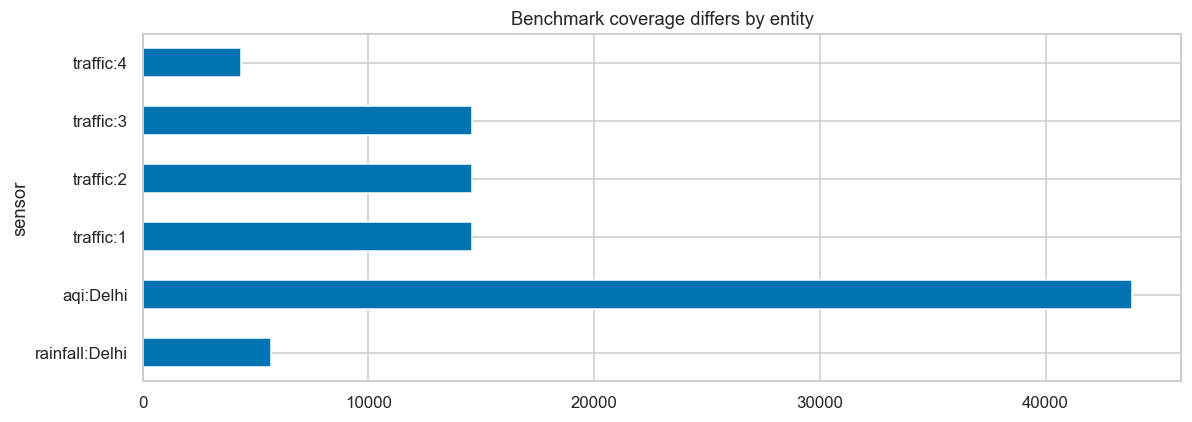

In [7]:
coverage=pd.DataFrame([{'sensor':k,'rows':len(h),'start':h.time.min(),'end':h.time.max(),
                       'missing':h.value.isna().sum(),'invalid':h.invalid.sum()} for k,h in histories.items()])
display(coverage)
coverage.plot.barh(x='sensor',y='rows',title='Benchmark coverage differs by entity',legend=False);plt.tight_layout();plt.show()

### 3.3 Missing measurements

Missingness is a monitoring signal in its own right. It does not prove a failed instrument.

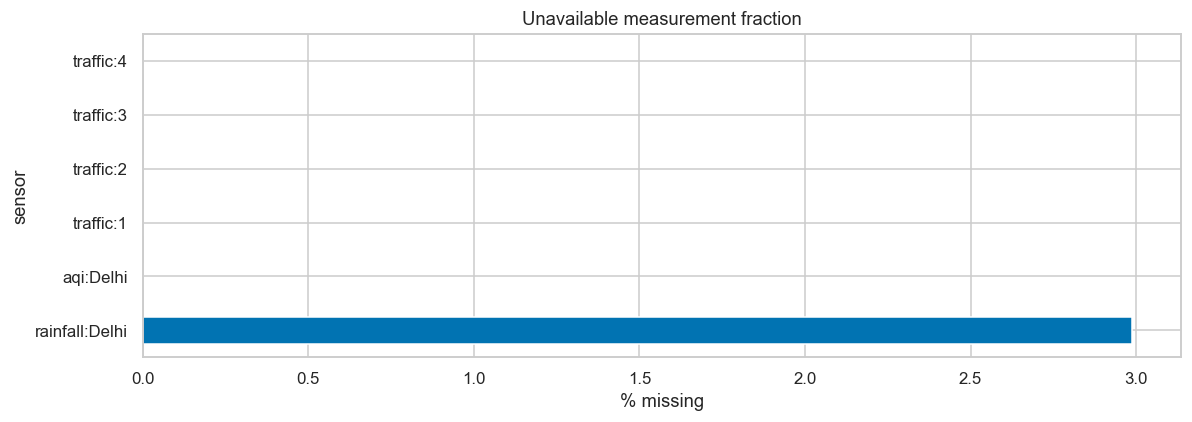

In [8]:
coverage.assign(missing_percent=100*coverage.missing/coverage.rows).plot.barh(x='sensor',y='missing_percent',legend=False,title='Unavailable measurement fraction',xlabel='% missing')
plt.tight_layout();plt.show()

### 3.4 Date spacing and reporting assumptions

Regular grids are required for rate-of-change and run-length features. Timestamp offsets/receipt times are not supplied by these files.

In [9]:
for sensor,h in histories.items():
    print(sensor,'interval counts',h.time.diff().value_counts().head(3).to_dict())
print('No receive_time, sequence_number or measured device health field is available.')

rainfall:Delhi interval counts {Timedelta('1 days 00:00:00'): 5690}
aqi:Delhi interval counts {Timedelta('0 days 01:00:00'): 43824}
traffic:1 interval counts {Timedelta('0 days 01:00:00'): 14591}
traffic:2 interval counts {Timedelta('0 days 01:00:00'): 14591}
traffic:3 interval counts {Timedelta('0 days 01:00:00'): 14591}
traffic:4 interval counts {Timedelta('0 days 01:00:00'): 4343}
No receive_time, sequence_number or measured device health field is available.


### 3.5 Numeric summaries and extreme records

Extremes are inspected and retained. Counts, rainfall and pollutant values have different units.

In [10]:
for sensor,h in histories.items():
    print(sensor,specs[sensor].unit)
    display(h.value.describe(percentiles=[.01,.5,.95,.99]).to_frame().T)
    display(h.nlargest(3,'value'))

rainfall:Delhi mm/day


,count,mean,std,min,1%,50%,95%,99%,max
value,5521.0,1.626147,5.953535,0.0,0.0,0.0,10.06,28.716,97.5


,sensor,time,value,invalid
4615,rainfall:Delhi,2021-08-21,97.50,0
4522,rainfall:Delhi,2021-05-20,78.45,0
5302,rainfall:Delhi,2023-07-09,76.20,0


aqi:Delhi ug/m3 (working assumption; source unit metadata incomplete)


,count,mean,std,min,1%,50%,95%,99%,max
value,43825.0,55.132466,29.040111,0.0,0.0,54.97169,102.433529,117.542333,154.582926


...

,count,mean,std,min,1%,50%,95%,99%,max
value,14592.0,13.69401,10.436005,1.0,2.0,11.0,30.0,51.0,180.0


,sensor,time,value,invalid
11539,traffic:3,2017-02-23 19:00:00,180.0,0
11540,traffic:3,2017-02-23 20:00:00,173.0,0
14390,traffic:3,2017-06-22 14:00:00,162.0,0


traffic:4 vehicles/hour


,count,mean,std,min,1%,50%,95%,99%,max
value,4344.0,7.251611,3.521455,1.0,1.0,7.0,13.0,18.0,36.0


,sensor,time,value,invalid
2609,traffic:4,2017-04-19 17:00:00,36.0,0
4142,traffic:4,2017-06-22 14:00:00,33.0,0
4260,traffic:4,2017-06-27 12:00:00,33.0,0


## 04. Exploratory analysis

Descriptive analytical EDA uses the early development period. Full-data coverage and data-quality audits are structural checks, not evidence for tuning a detector on final outcomes. Each panel retains its entity and unit; no cross-source physical interpretation is implied.

### 4.1 Causal feature materialization and periods

Features are computed forward in time, separately by entity. Each source has a 60% development / 20% validation / 20% final-period split. All traffic junctions share the source cutoff.

In [11]:
feature_frames=[causal_features(h,specs[sensor]) for sensor,h in histories.items()]
features,boundaries=assign_periods(pd.concat(feature_frames,ignore_index=True))
train=features[features.period.eq('train') & features.ready].copy()
validation=features[features.period.eq('validation') & features.ready].copy()
test=features[features.period.eq('test') & features.ready].copy()
eda=features[features.period.eq('train')].copy()
print(json.dumps(boundaries,indent=2))
display(features.groupby(['sensor','period']).size().unstack(fill_value=0))
(OUT/'temporal_boundaries.json').write_text(json.dumps(boundaries,indent=2))

{
  "aqi": {
    "train_end_exclusive": "2021-12-31T15:00:00.000000000",
    "test_start": "2022-12-31T20:00:00.000000000"
  },
  "rainfall": {
    "train_end_exclusive": "2018-05-08T00:00:00.000000000",
    "test_start": "2021-06-19T00:00:00.000000000"
  },
  "traffic": {
    "train_end_exclusive": "2016-10-30T19:00:00.000000000",
    "test_start": "2017-03-01T09:00:00.000000000"
  }
}


period,test,train,validation
sensor,,,
aqi:Delhi,8765,26295,8765
rainfall:Delhi,1139,3414,1138
traffic:1,2919,8755,2918
traffic:2,2919,8755,2918
traffic:3,2919,8755,2918
traffic:4,2919,0,1425


389

### 4.2 Per-entity distributions

Raw and log views reveal asymmetry and heavy tails without deleting events or transforming the source measurements.

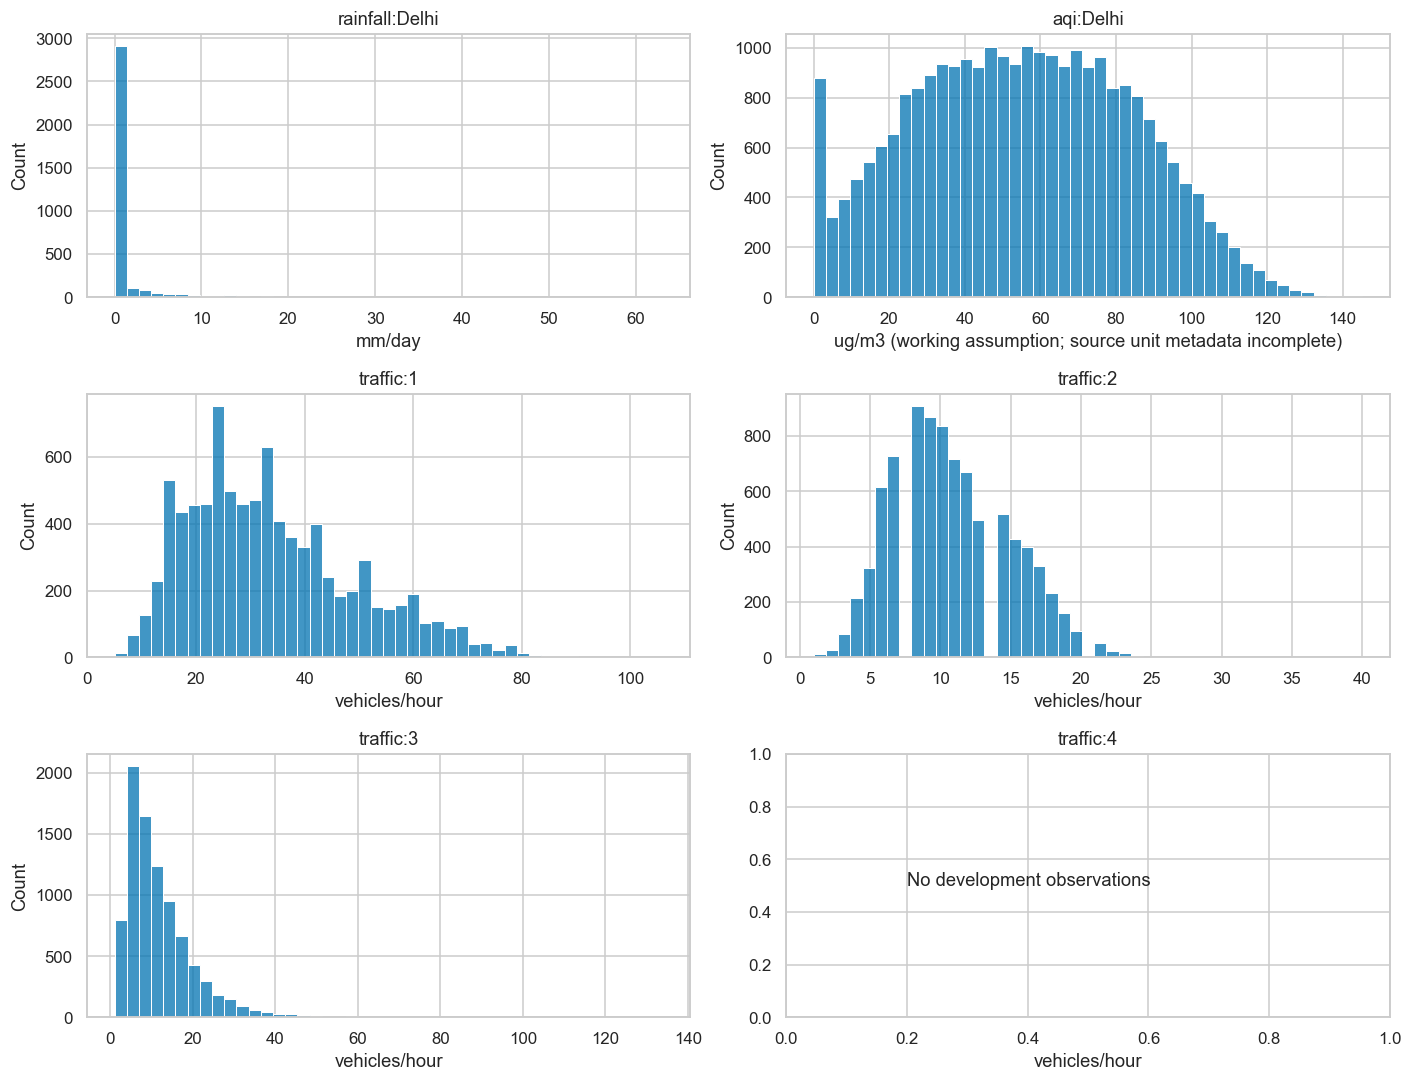

In [12]:
sensors=list(histories)
fig,axes=plt.subplots(3,2,figsize=(13,10))
for sensor,ax in zip(sensors,axes.flat):
    sample=eda[eda.sensor.eq(sensor)].value
    if len(sample):sns.histplot(sample,bins=45,ax=ax)
    else:ax.text(.2,.5,'No development observations',transform=ax.transAxes)
    ax.set_title(sensor);ax.set_xlabel(specs[sensor].unit)
plt.tight_layout();plt.show()

### 4.3 Monthly time patterns

A change in traffic demand or pollution season can increase alert rate without any equipment fault.

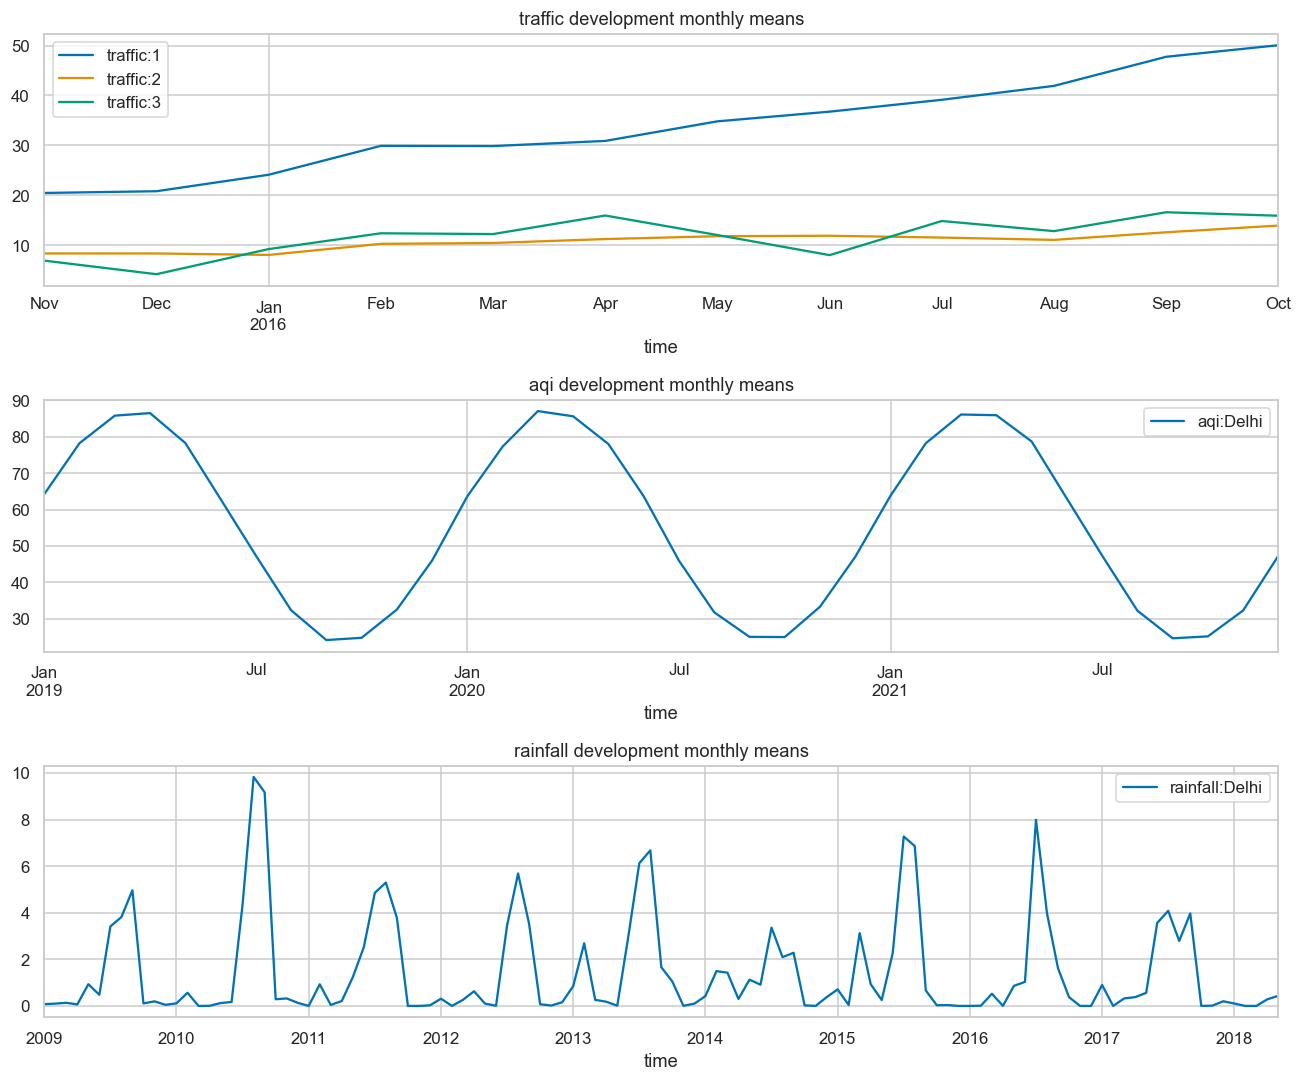

In [13]:
fig,axes=plt.subplots(3,1,figsize=(12,10))
for family,ax in zip(['traffic','aqi','rainfall'],axes):
    subset=eda[eda.sensor.str.startswith(family+':')]
    for sensor,g in subset.groupby('sensor'):
        g.set_index('time').value.resample('MS').mean().plot(ax=ax,label=sensor)
    ax.set_title(family+' development monthly means');ax.legend()
plt.tight_layout();plt.show()

### 4.4 Seasonal structure

Known calendar patterns motivate causal seasonal residuals, rather than treating every daily peak as abnormal.

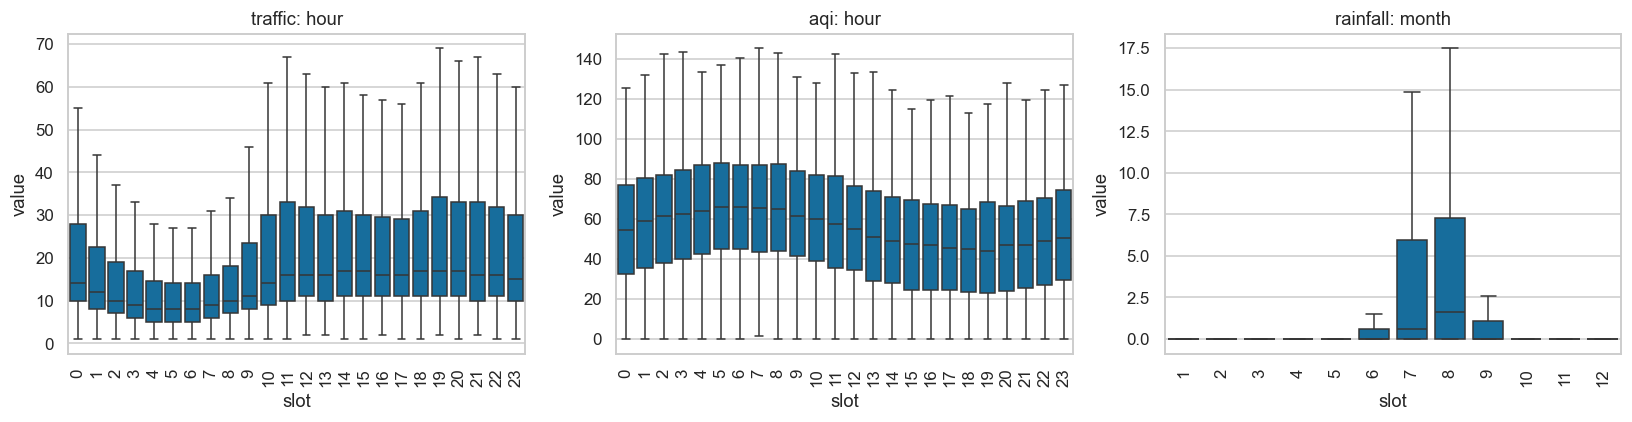

In [14]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for family,ax in zip(['traffic','aqi','rainfall'],axes):
    subset=eda[eda.sensor.str.startswith(family+':')].copy()
    subset['slot']=subset.time.dt.month if family=='rainfall' else subset.time.dt.hour
    sns.boxplot(data=subset,x='slot',y='value',showfliers=False,ax=ax)
    ax.set_title(family+': month' if family=='rainfall' else family+': hour');ax.tick_params(axis='x',rotation=90)
plt.tight_layout();plt.show()

### 4.5 Junction differences

Separate models prevent a busy junction’s baseline from being imposed on another junction.

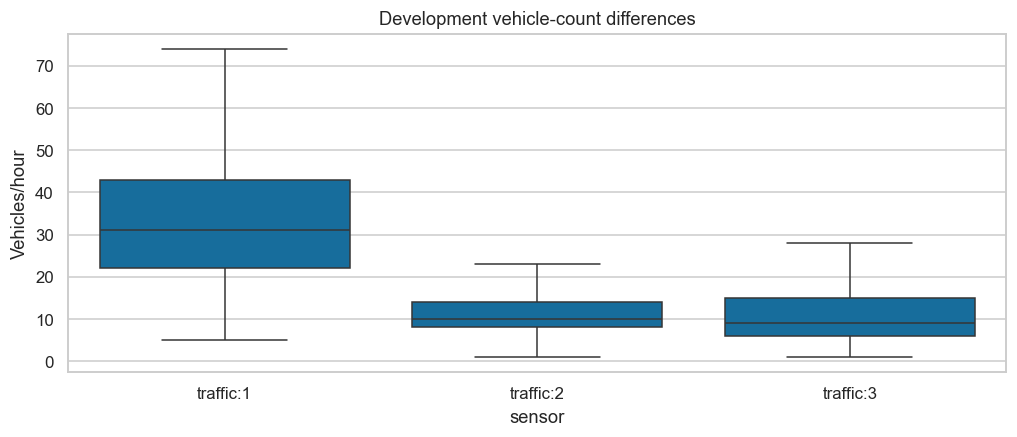

In [15]:
traffic_eda=eda[eda.sensor.str.startswith('traffic:')]
sns.boxplot(data=traffic_eda,x='sensor',y='value',showfliers=False)
plt.title('Development vehicle-count differences');plt.ylabel('Vehicles/hour');plt.show()

### 4.6 Rolling references around real extremes

The shaded reference uses earlier readings only. An extreme rainfall day can be a genuine event rather than a sensor error.

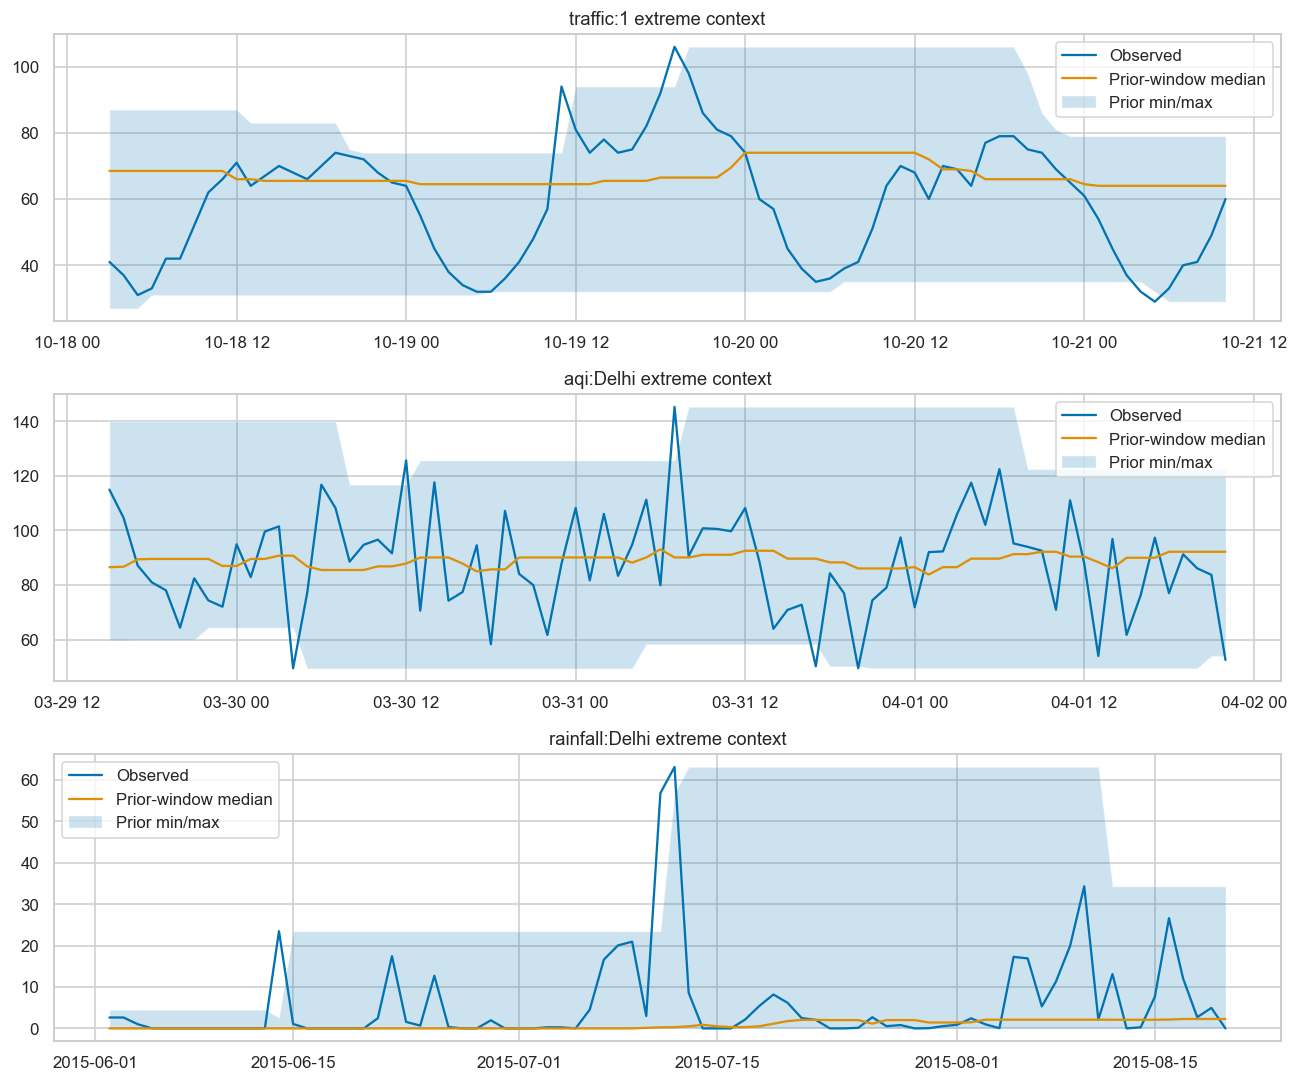

In [16]:
fig,axes=plt.subplots(3,1,figsize=(12,10))
for sensor,ax in zip(['traffic:1','aqi:Delhi','rainfall:Delhi'],axes):
    g=eda[eda.sensor.eq(sensor)].reset_index(drop=True)
    peak=int(g.value.fillna(-1).argmax());z=g.iloc[max(0,peak-40):peak+40]
    ax.plot(z.time,z.value,label='Observed');ax.plot(z.time,z.rolling_median,label='Prior-window median')
    ax.fill_between(z.time,z.rolling_min,z.rolling_max,alpha=.2,label='Prior min/max')
    ax.set_title(sensor+' extreme context');ax.legend()
plt.tight_layout();plt.show()

### 4.7 Correlation and redundancy

Rolling mean, median and min/max are correlated. Their isolation diagnostics must not be interpreted as independent causal effects.

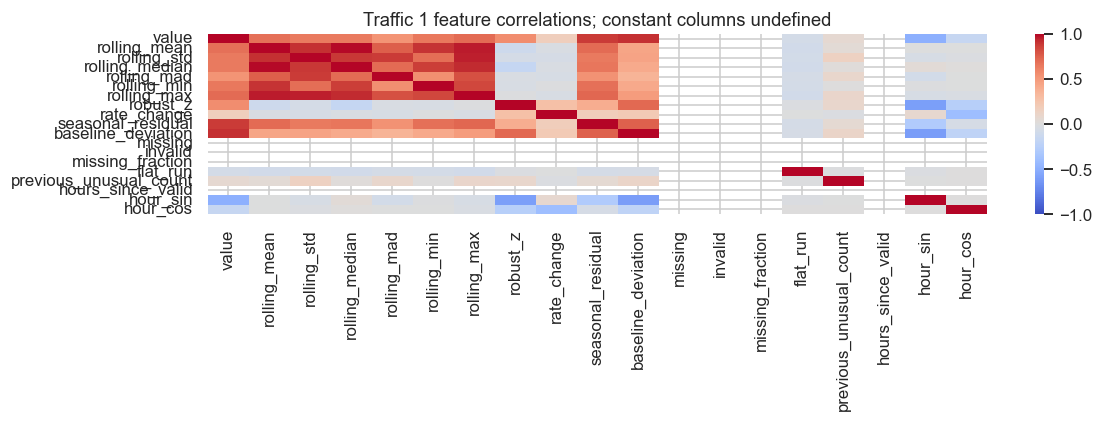

In [17]:
correlation=train[train.sensor.eq('traffic:1')][FEATURES].corr()
sns.heatmap(correlation,cmap='coolwarm',center=0,vmin=-1,vmax=1)
plt.title('Traffic 1 feature correlations; constant columns undefined');plt.tight_layout();plt.show()

### 4.8 Repeated values and reporting anomalies

Repeated integer traffic counts are natural at low flows; sustained identical values are only candidates for investigation. Dry rainfall spells are not flagged as failed sensors.

,max_equal_run,missing_fraction,invalid_fraction
sensor,,,
aqi:Delhi,4,0.0,0.0
rainfall:Delhi,99,0.0,0.0
traffic:1,4,0.0,0.0
traffic:2,5,0.0,0.0
traffic:3,5,0.0,0.0


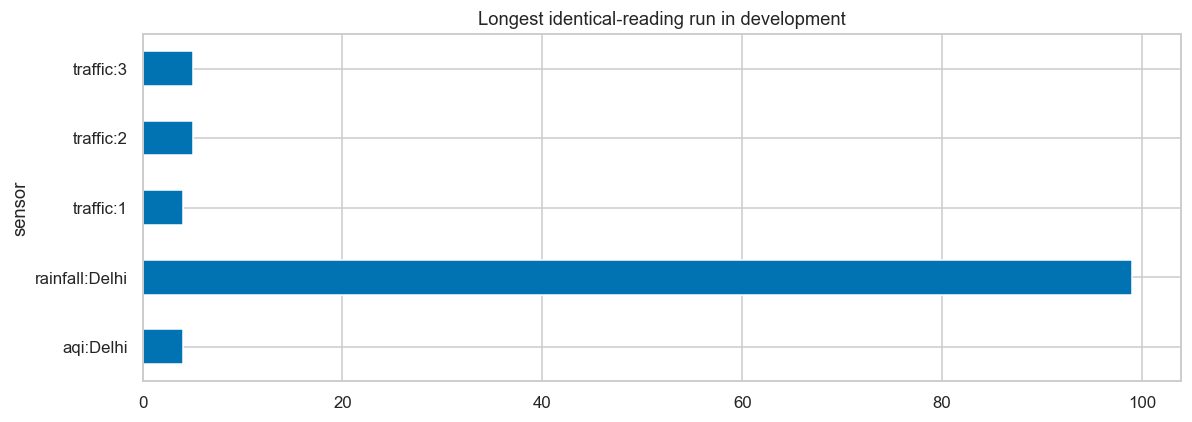

In [18]:
run_table=eda.groupby('sensor').agg(max_equal_run=('flat_run','max'),missing_fraction=('missing','mean'),invalid_fraction=('invalid','mean'))
display(run_table)
run_table.max_equal_run.plot.barh(title='Longest identical-reading run in development');plt.tight_layout();plt.show()

## 05. Preprocessing and leakage controls

Raw history is ordered and regularized at the declared cadence. Conflicting duplicates and off-grid observations are rejected. Missing intervals remain explicit. Invalidity is retained alongside missingness. Median imputation is fitted on each sensor’s historical development features only; it is not a claim that missing readings are physically normal. Tree-based Isolation Forest does not require feature standardization, and models are not pooled across units or entities.

The temporal question differs from forecasting: the current value is available when detecting a current anomaly. Its reference window must nevertheless exclude the current value. Model training ends before any validation/test score. Calibration scores do not establish fault probability.

### 5.1 Future perturbation invariant

Changing future measurements cannot change earlier features, including seasonal baselines and previous unusual counts.

In [19]:
sensor='traffic:1';original=histories[sensor];changed=original.copy()
cut=len(original)//2;changed.loc[cut:,'value']=999999
fa=causal_features(original,specs[sensor]);fb=causal_features(changed,specs[sensor])
pd.testing.assert_frame_equal(fa.iloc[:cut],fb.iloc[:cut])
print('PASS: future observations do not alter past features')

PASS: future observations do not alter past features


### 5.2 Missing/invalid demonstration on a copy

This is an isolated fixture, not evidence that the original file contained a bad reading.

In [20]:
copy=histories['traffic:1'].head(120).copy()
copy.loc[100,'value']=-1;copy.loc[101,'value']=np.nan
copy=copy.drop(index=102)
check=causal_features(copy,specs['traffic:1'])
display(check.loc[98:104,['time','value','invalid','missing','rolling_median','rate_change']])
assert check.loc[100,'invalid']==1 and check.loc[102,'missing']==1

,time,value,invalid,missing,rolling_median,rate_change
98,2015-11-05 02:00:00,18.0,0,0,23.5,-2.0
99,2015-11-05 03:00:00,13.0,0,0,23.5,-5.0
100,2015-11-05 04:00:00,NaN,1,1,23.5,NaN
101,2015-11-05 05:00:00,NaN,0,1,24.0,NaN
102,2015-11-05 06:00:00,NaN,0,1,24.0,NaN
103,2015-11-05 07:00:00,12.0,0,0,24.0,NaN
104,2015-11-05 08:00:00,15.0,0,0,24.0,3.0


### 5.3 Current observation excluded from baseline

A spike should change its deviation, not retrospectively change its own reference median or previous-event count.

In [21]:
h=histories['traffic:1'].head(400).copy();modified=h.copy();modified.loc[300,'value']=100000
before=causal_features(h,specs['traffic:1']);after=causal_features(modified,specs['traffic:1'])
for column in ['rolling_mean','rolling_median','rolling_mad','seasonal_expected','previous_unusual_count']:
    assert before.loc[300,column]==after.loc[300,column]
print('PASS: current reading excluded from reference statistics')

PASS: current reading excluded from reference statistics


## 06. Feature engineering and interpretation

For hourly series the rolling reference is the previous 24 readings; rainfall uses 30 days. These windows are declared assumptions. The robust scale is `max(1.4826 × prior MAD, unit-scale floor)` so a constant/zero series cannot cause division by zero. Floors are 1 vehicle/source PM2.5 unit and 0.1 mm. They are numerical research choices, not instrument accuracy claims.

Seasonal expectation is an **expanding, shifted same-slot mean**: month for daily rainfall, weekday×hour for hourly series. Sparse slots fall back to the prior global mean. This adapts using past observations and can gradually absorb a persistent shift. No full-sample seasonal profile is used to score earlier rows.

### 6.1 Feature schema

Previous unusual-event count means prior robust-threshold crossings, not known incidents or confirmed faults.

In [22]:
feature_schema=pd.DataFrame([
 ['value','Current cleaned reading','source units'],
 ['rolling_mean / std / median / MAD / min / max','Strictly preceding reference window','source units'],
 ['robust_z','(current − prior median) / floored scaled MAD','dimensionless'],
 ['rate_change','Current minus preceding cadence reading','source units per cadence'],
 ['seasonal_residual','Current minus past-only same-slot baseline','source units'],
 ['baseline_deviation','Deviation from past-only expanding mean/std','dimensionless'],
 ['missing / invalid','Current reporting quality','binary'],
 ['missing_fraction','Missing share in preceding reference window','fraction'],
 ['flat_run','Consecutive identical observed values, including current','readings'],
 ['previous_unusual_count','Prior abs(robust_z)>6 crossings in window','count, not incidents'],
 ['hours_since_valid','Time since most recent finite nonnegative reading','hours'],
 ['hour_sin / cos','Known time-of-day phase','dimensionless']
],columns=['feature_family','definition','unit'])
display(feature_schema)
feature_schema.to_csv(OUT/'feature_definitions.csv',index=False)
(OUT/'feature_schema.json').write_text(json.dumps({'ordered_features':FEATURES,'dtypes':{k:str(features[k].dtype) for k in FEATURES}},indent=2))

,feature_family,definition,unit
0,value,Current cleaned reading,source units
1,rolling_mean / std / median / MAD / min / max,Strictly preceding reference window,source units
2,robust_z,(current − prior median) / floored scaled MAD,dimensionless
3,rate_change,Current minus preceding cadence reading,source units per cadence
4,seasonal_residual,Current minus past-only same-slot baseline,source units
5,baseline_deviation,Deviation from past-only expanding mean/std,dimensionless
6,missing / invalid,Current reporting quality,binary
7,missing_fraction,Missing share in preceding reference window,fraction
8,flat_run,"Consecutive identical observed values, includi...",readings
9,previous_unusual_count,Prior abs(robust_z)>6 crossings in window,"count, not incidents"


999

### 6.2 Visualize current versus reference features

Feature excursions can indicate legitimate changes; the interpretation remains conditional on provenance.

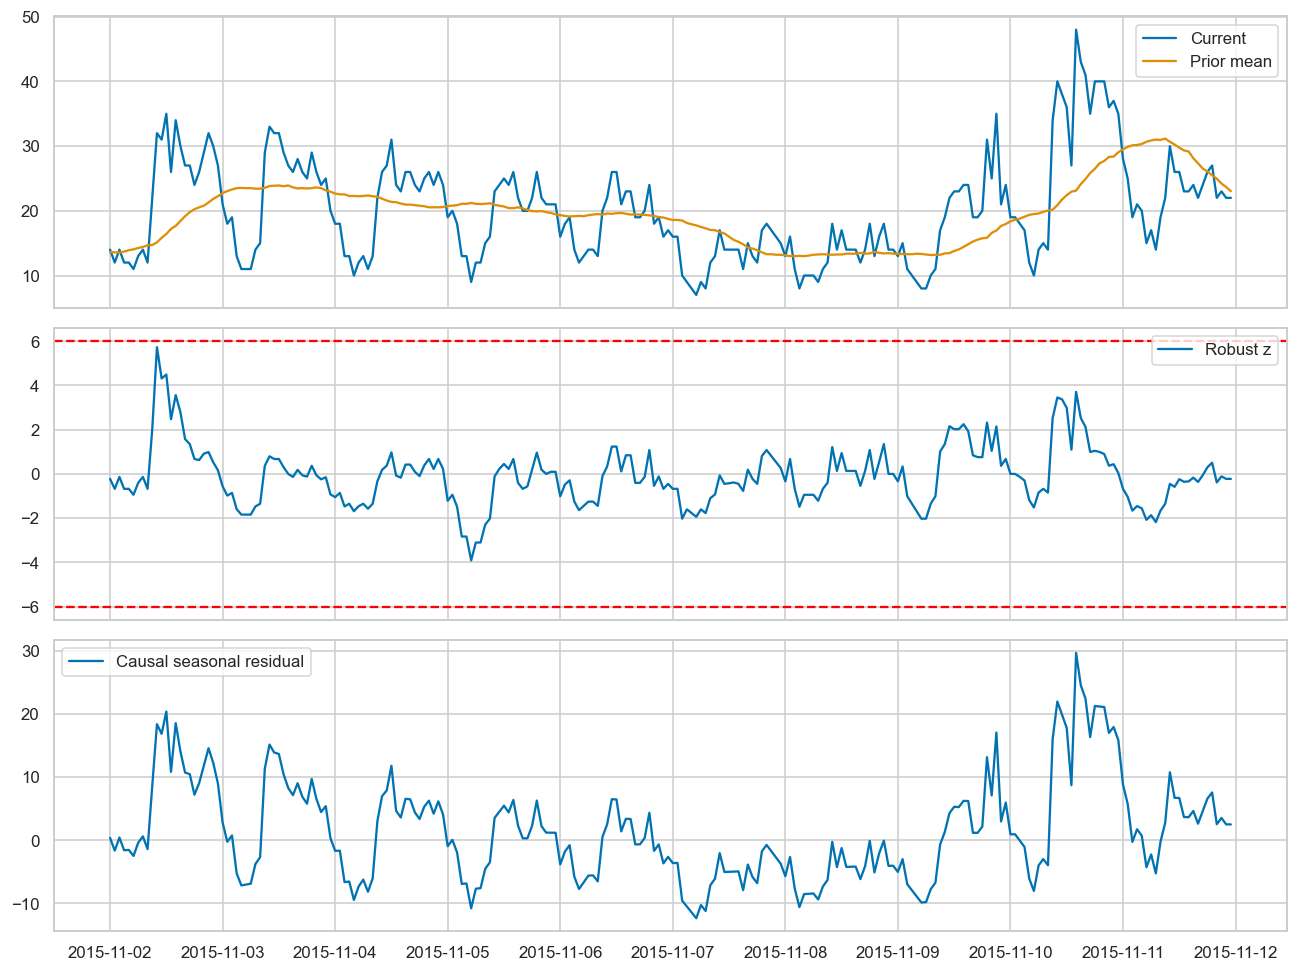

In [23]:
g=train[train.sensor.eq('traffic:1')].head(240)
fig,ax=plt.subplots(3,1,figsize=(12,9),sharex=True)
ax[0].plot(g.time,g.value,label='Current');ax[0].plot(g.time,g.rolling_mean,label='Prior mean');ax[0].legend()
ax[1].plot(g.time,g.robust_z,label='Robust z');ax[1].axhline(6,color='red',ls='--');ax[1].axhline(-6,color='red',ls='--');ax[1].legend()
ax[2].plot(g.time,g.seasonal_residual,label='Causal seasonal residual');ax[2].legend()
plt.tight_layout();plt.show()

### 6.3 Inspect causal availability

No target, known-fault label, municipality identifier or synthetic depth enters these models.

In [24]:
display(train[['sensor','time']+FEATURES].head(8))
assert not {'target','depth_m','failure','fault_label','event_id'}.intersection(FEATURES)
print('All',len(FEATURES),'features are numeric; no cross-entity encoding is fitted.')

,sensor,time,value,rolling_mean,rolling_std,rolling_median,rolling_mad,rolling_min,rolling_max,robust_z,...,seasonal_residual,baseline_deviation,missing,invalid,missing_fraction,flat_run,previous_unusual_count,hours_since_valid,hour_sin,hour_cos
24,aqi:Delhi,2019-01-02 00:00:00,72.206394,61.602411,18.073439,60.888543,10.600176,24.225843,100.624724,0.720157,...,10.603982,0.586716,0,0,0.0,1,0.0,0.0,0.000000,1.000000e+00
25,aqi:Delhi,2019-01-02 01:00:00,42.517738,61.477838,17.985759,60.888543,10.600176,24.225843,100.624724,-1.168937,...,-19.508833,-1.094799,0,0,0.0,1,0.0,0.0,0.258819,9.659258e-01
26,aqi:Delhi,2019-01-02 02:00:00,72.801279,60.522251,18.370570,57.240837,10.370326,24.225843,100.624724,1.012058,...,11.525048,0.644801,0,0,0.0,1,0.0,0.0,0.500000,8.660254e-01
27,aqi:Delhi,2019-01-02 03:00:00,62.040109,62.546227,16.807116,60.888543,11.105724,35.977284,100.624724,0.069939,...,0.337025,0.019077,0,0,0.0,1,0.0,0.0,0.707107,7.071068e-01
28,aqi:Delhi,2019-01-02 04:00:00,73.660792,62.420524,16.798801,59.802477,10.994019,35.977284,100.624724,0.850217,...,11.945671,0.689052,0,0,0.0,1,0.0,0.0,0.866025,5.000000e-01
29,aqi:Delhi,2019-01-02 05:00:00,74.006964,62.551944,16.876967,59.802477,11.378302,35.977284,100.624724,0.842023,...,11.879923,0.691985,0,0,0.0,1,0.0,0.0,0.965926,2.588190e-01
30,aqi:Delhi,2019-01-02 06:00:00,92.381438,62.048246,16.314778,59.802477,11.378302,35.977284,100.624724,1.931238,...,29.858400,1.755533,0,0,0.0,1,0.0,0.0,1.000000,6.123234e-17
31,aqi:Delhi,2019-01-02 07:00:00,63.477628,63.122209,17.437591,59.802477,11.938353,35.977284,100.624724,0.207638,...,-0.008584,-0.000489,0,0,0.0,1,0.0,0.0,0.965926,-2.588190e-01


All 19 features are numeric; no cross-entity encoding is fitted.


## 07. Historical development and baseline detectors

**Rules:** current missing/invalid reading, sufficiently long identical run, value above the training 99.5th percentile, or absolute cadence change above its training 99.5th percentile. Flatline thresholds are 12 hourly readings / 5 daily readings; zero-rainfall runs are exempt. These are inspectable research rules, not physical upper safety limits.

**Robust detector:** abs(robust z)>6 against a strictly prior median/MAD. Missing z is not treated as measured normality; quality alerts are separate.

**Isolation Forest:** randomized partition trees isolate sparse feature combinations in shorter paths. We report `−score_samples`, so larger means more unusual; alert iff score is **strictly greater** than `−offset_`. Contamination=0.02 sets a training-score cutoff; it is **not a measured failure prevalence**. Training may already contain unusual events.

The component uses Isolation Forest plus independent quality rules for a review signal. Raw rules, robust and isolation results stay separately available. No precision-based model winner can be selected without labels. We prespecify 100 trees, 256 subsamples and 2% contamination; sensitivity experiments investigate this choice without test-based retuning. See [scikit-learn outlier detection](https://scikit-learn.org/stable/modules/outlier_detection.html) and [Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html); the installed version is recorded in artifacts.

### 7.1 Fit only supported development histories

Junction 4 has no development-period rows under the shared traffic cutoff. It is withheld as a naturally unseen identity.

In [25]:
suites={};fit_rows=[]
for sensor,g in train.groupby('sensor'):
    if len(g)<100:continue
    model=DetectorSuite(specs[sensor],n_estimators=100,max_samples=256,contamination=.02,seed=SEED).fit(g)
    suites[sensor]=model
    fit_rows.append({'sensor':sensor,'fit_rows':model.fit_rows_,'train_last':str(model.train_end_),
                     'rule_upper':model.upper_,'jump_threshold':model.jump_,'isolation_threshold':model.isolation_threshold_})
fit_table=pd.DataFrame(fit_rows)
display(fit_table)
print('Untrained identities:',sorted(set(specs)-set(suites)))
fit_table.to_csv(OUT/'fitted_thresholds.csv',index=False)

,sensor,fit_rows,train_last,rule_upper,jump_threshold,isolation_threshold
0,aqi:Delhi,26271,2021-12-31 14:00:00,122.233986,62.713949,0.551176
1,rainfall:Delhi,3384,2018-05-07 00:00:00,36.299550,38.236350,0.645244
2,traffic:1,8731,2016-10-30 18:00:00,79.000000,20.000000,0.573869
3,traffic:2,8731,2016-10-30 18:00:00,22.000000,8.000000,0.557178
4,traffic:3,8731,2016-10-30 18:00:00,56.000000,26.000000,0.613730


Untrained identities: ['traffic:4']


### 7.2 Score validation without learning from it

Only the train-fitted imputer and detector are used. Validation scores describe behavior; they are not fault labels.

In [26]:
def score_period(frame):
    parts=[]
    for sensor,model in suites.items():
        subset=frame[frame.sensor.eq(sensor)]
        if len(subset):parts.append(model.score(subset))
    return pd.concat(parts,ignore_index=True)
val_scores=score_period(validation)
display(val_scores.head())
alert_columns=['rule_alert','robust_alert','isolation_alert','quality_alert','review_alert']
validation_rates=val_scores.groupby('sensor')[alert_columns].mean()
display(validation_rates)
validation_rates.to_csv(OUT/'validation_alert_rates.csv')

,sensor,time,value,ready,missing,invalid,hours_since_valid,rule_score,rule_alert,robust_score,robust_alert,isolation_score,isolation_alert,quality_alert,review_alert,violated_rules
0,aqi:Delhi,2021-12-31 15:00:00,40.175503,True,0,0,0.0,1.014737,True,0.752499,False,0.468155,False,False,False,abrupt_change
1,aqi:Delhi,2021-12-31 16:00:00,50.557261,True,0,0,0.0,0.413611,False,0.118760,False,0.432656,False,False,False,
2,aqi:Delhi,2021-12-31 17:00:00,44.502269,True,0,0,0.0,0.364074,False,0.446983,False,0.434532,False,False,False,
3,aqi:Delhi,2021-12-31 18:00:00,53.755142,True,0,0,0.0,0.439772,False,0.260727,False,0.445992,False,False,False,
4,aqi:Delhi,2021-12-31 19:00:00,45.629761,True,0,0,0.0,0.373298,False,0.388694,False,0.441759,False,False,False,


,rule_alert,robust_alert,isolation_alert,quality_alert,review_alert
sensor,,,,,
aqi:Delhi,0.014147,0.000228,0.026811,0.000000,0.026811
rainfall:Delhi,0.026362,0.139719,0.014060,0.019332,0.033392
traffic:1,0.130912,0.002056,0.309116,0.000000,0.309116
traffic:2,0.093215,0.002056,0.232351,0.000000,0.232351
traffic:3,0.017820,0.014393,0.042152,0.000000,0.042152


### 7.3 Validation alert comparison

Higher alert rate is neither better recall nor more confirmed failures.

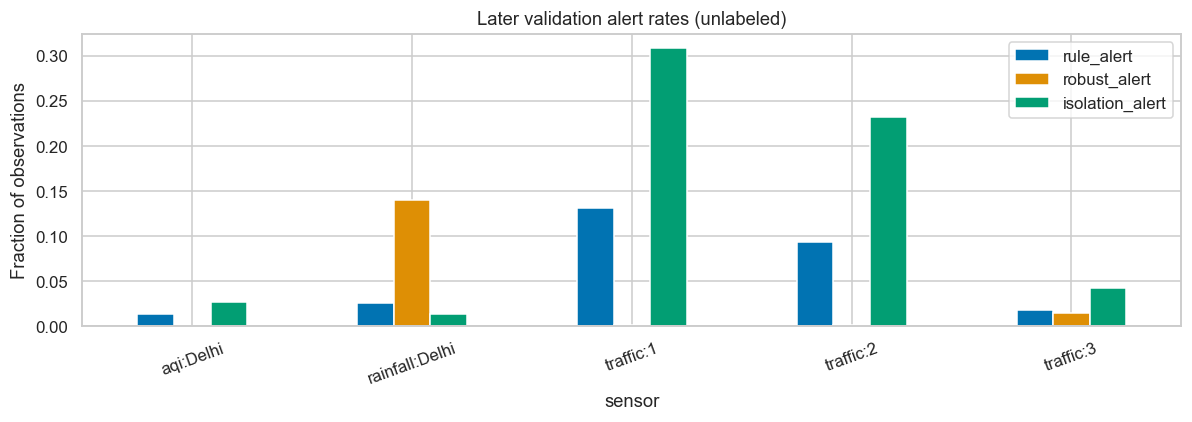

In [27]:
validation_rates[['rule_alert','robust_alert','isolation_alert']].plot.bar(title='Later validation alert rates (unlabeled)',ylabel='Fraction of observations',rot=20)
plt.tight_layout();plt.show()

### 7.4 Score distributions and threshold semantics

Each detector uses a different scale. Scores must not be averaged into a single risk probability.

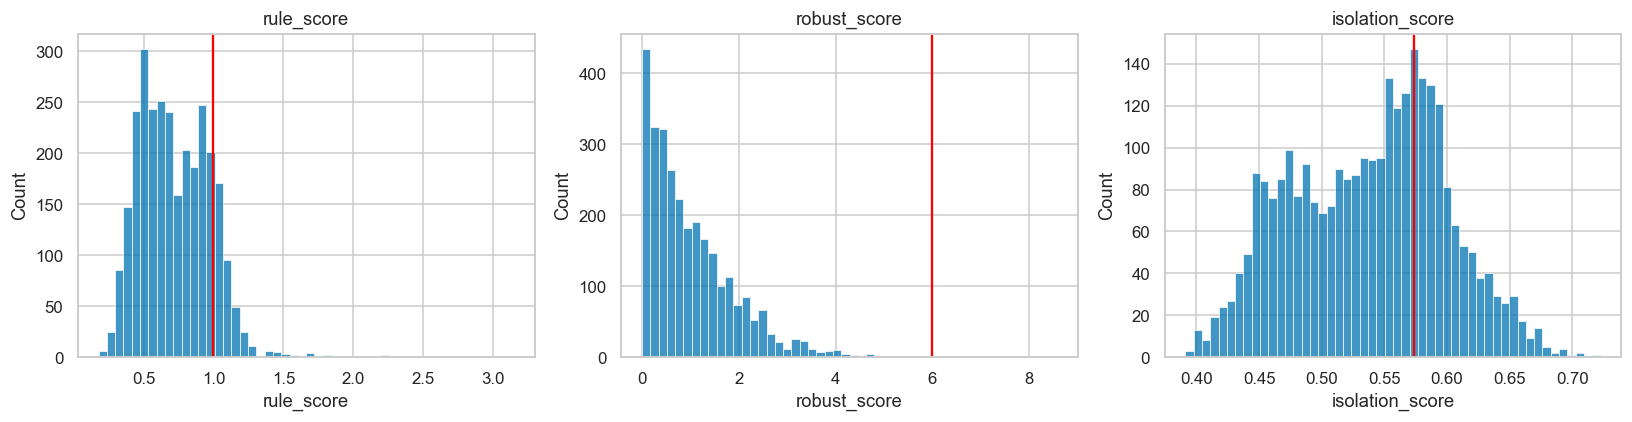

In [28]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
z=val_scores[val_scores.sensor.eq('traffic:1')]
for column,a in zip(['rule_score','robust_score','isolation_score'],ax):
    sns.histplot(z[column].dropna(),bins=50,ax=a);a.set_title(column)
ax[0].axvline(1,color='red');ax[1].axvline(6,color='red');ax[2].axvline(suites['traffic:1'].isolation_threshold_,color='red')
plt.tight_layout();plt.show()

## 08. Temporal validation and hyperparameter sensitivity

No labels are manufactured for historical observations. Expanding-origin validation reports alert rate, score quantiles and seed agreement instead of supervised accuracy. Hyperparameters are investigated transparently, and the predeclared final configuration remains unchanged. The final period and final injected fixtures are still reserved.

### 8.1 Expanding-origin validation

This uses only the original development segment. Each fold refits imputation and detector on its own earlier subset.

,fold,training_rows,validation_rows,last_train,first_validation,alert_rate,score_p50,score_p95
0,0,2185,2182,2016-02-01 00:00:00,2016-02-01 01:00:00,0.118240,0.506441,0.588817
1,1,4367,2182,2016-05-01 22:00:00,2016-05-01 23:00:00,0.427589,0.547351,0.647494
2,2,6549,2182,2016-07-31 20:00:00,2016-07-31 21:00:00,0.263520,0.532163,0.625233


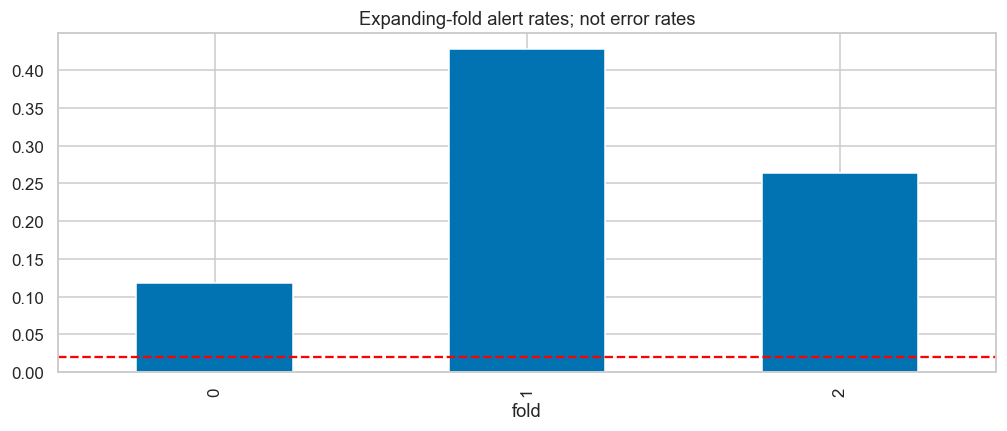

In [29]:
from sklearn.model_selection import TimeSeriesSplit
cv=[]
z=train[train.sensor.eq('traffic:1')].reset_index(drop=True)
for fold,(tr,va) in enumerate(TimeSeriesSplit(n_splits=3).split(z)):
    model=DetectorSuite(specs['traffic:1'],n_estimators=100,max_samples=256,contamination=.02,seed=SEED).fit(z.iloc[tr])
    scored=model.score(z.iloc[va])
    cv.append({'fold':fold,'training_rows':len(tr),'validation_rows':len(va),'last_train':str(z.iloc[tr].time.max()),
               'first_validation':str(z.iloc[va].time.min()),'alert_rate':scored.isolation_alert.mean(),
               'score_p50':scored.isolation_score.median(),'score_p95':scored.isolation_score.quantile(.95)})
cv=pd.DataFrame(cv);display(cv);cv.to_csv(OUT/'temporal_cv_diagnostics.csv',index=False)
cv.plot.bar(x='fold',y='alert_rate',legend=False,title='Expanding-fold alert rates; not error rates');plt.axhline(.02,color='red',ls='--');plt.show()

### 8.2 Contamination assumptions

Changing contamination changes the score threshold, not evidence that anomalies are real faults. Hold tree settings and seed constant for a controlled comparison.

,sensor,assumed_contamination,threshold,validation_alert_rate
0,aqi:Delhi,0.005,0.577257,0.007644
1,aqi:Delhi,0.010,0.564183,0.014718
2,aqi:Delhi,0.020,0.551176,0.026811
3,aqi:Delhi,0.050,0.529715,0.058186
4,aqi:Delhi,0.100,0.511314,0.107929
5,rainfall:Delhi,0.005,0.693965,0.003515
6,rainfall:Delhi,0.010,0.673619,0.007909
7,rainfall:Delhi,0.020,0.645244,0.014060
8,rainfall:Delhi,0.050,0.580976,0.037786
9,rainfall:Delhi,0.100,0.526184,0.104569


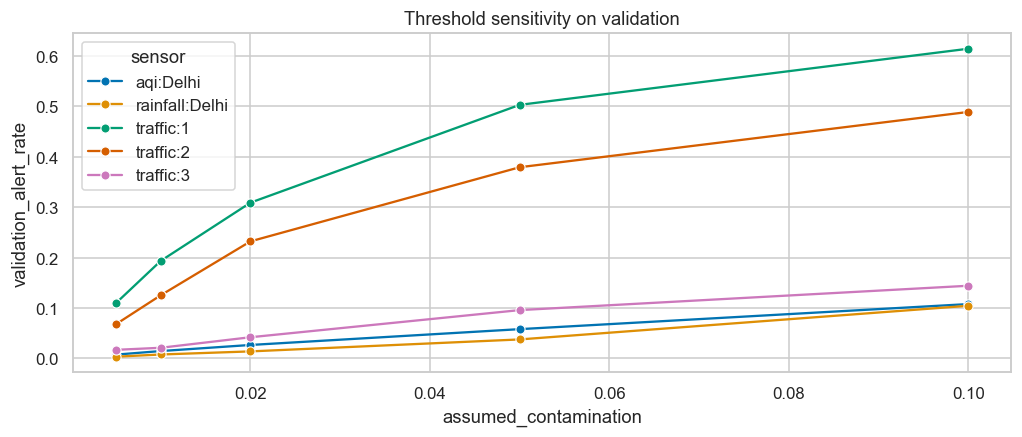

In [30]:
contamination_rows=[]
for sensor in suites:
    tr=train[train.sensor.eq(sensor)];va=validation[validation.sensor.eq(sensor)]
    for contamination in [.005,.01,.02,.05,.10]:
        model=DetectorSuite(specs[sensor],100,256,contamination,SEED).fit(tr)
        out=model.score(va)
        contamination_rows.append({'sensor':sensor,'assumed_contamination':contamination,'threshold':model.isolation_threshold_,
                                   'validation_alert_rate':out.isolation_alert.mean()})
contamination_results=pd.DataFrame(contamination_rows)
display(contamination_results)
sns.lineplot(data=contamination_results,x='assumed_contamination',y='validation_alert_rate',hue='sensor',marker='o')
plt.title('Threshold sensitivity on validation');plt.show()
contamination_results.to_csv(OUT/'contamination_sensitivity.csv',index=False)

### 8.3 Tree count, subsampling and seed stability

Rank agreement and alert-set Jaccard quantify reproducibility, not diagnostic correctness. We do not optimize these using final-period data.

,trees,subsamples,seed,alert_rate,rank_correlation,alert_jaccard
0,64,128,42,0.349897,0.971042,0.767463
1,64,128,73,0.342015,0.964554,0.743119
2,100,256,42,0.309116,1.000000,1.000000
3,100,256,73,0.408499,0.975296,0.699675
4,160,512,42,0.384510,0.981968,0.761532
5,160,512,73,0.273475,0.978956,0.783841


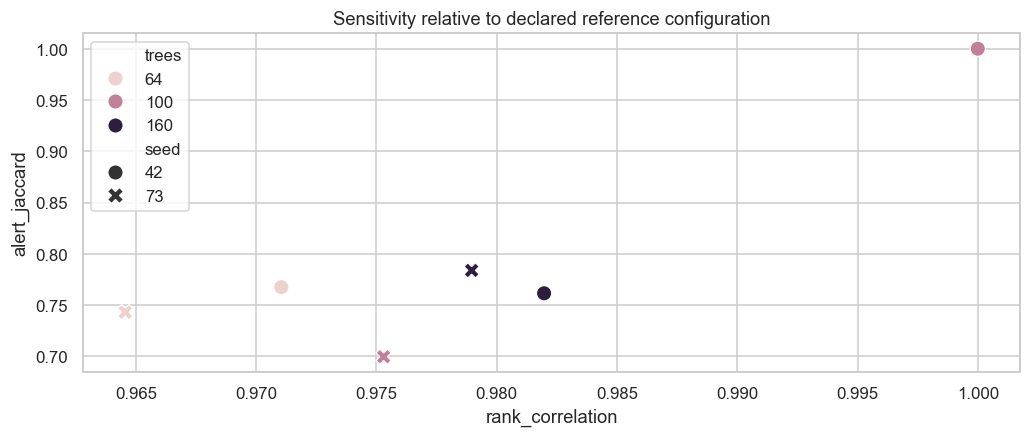

In [31]:
from scipy.stats import spearmanr
sensitivity=[];tr=train[train.sensor.eq('traffic:1')];va=validation[validation.sensor.eq('traffic:1')]
reference=suites['traffic:1'].score(va)
for trees,samples in [(64,128),(100,256),(160,512)]:
    for seed in [42,73]:
        candidate=DetectorSuite(specs['traffic:1'],trees,samples,.02,seed).fit(tr)
        scored=candidate.score(va)
        a=scored.isolation_alert.to_numpy();b=reference.isolation_alert.to_numpy()
        sensitivity.append({'trees':trees,'subsamples':samples,'seed':seed,'alert_rate':a.mean(),
                            'rank_correlation':spearmanr(scored.isolation_score,reference.isolation_score).statistic,
                            'alert_jaccard':np.sum(a&b)/max(1,np.sum(a|b))})
sensitivity=pd.DataFrame(sensitivity);display(sensitivity)
sensitivity.to_csv(OUT/'hyperparameter_stability.csv',index=False)
sns.scatterplot(data=sensitivity,x='rank_correlation',y='alert_jaccard',hue='trees',style='seed',s=100)
plt.title('Sensitivity relative to declared reference configuration');plt.show()

### 8.4 Sensitivity to seasonal features

An ablation drops seasonal residual and calendar phase while keeping raw data and training period fixed. Alert disagreement does not establish which detector is correct.

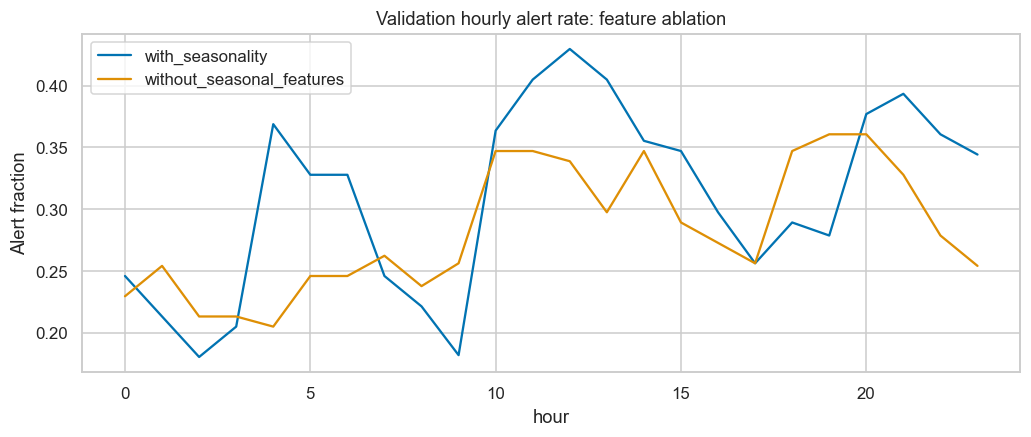

Disagreement fraction: 0.07847840986977382


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
nonseasonal=[f for f in FEATURES if f not in ['seasonal_residual','hour_sin','hour_cos']]
ablation=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),('model',IsolationForest(n_estimators=100,max_samples=256,contamination=.02,random_state=SEED,n_jobs=2))])
ablation.fit(tr[nonseasonal])
no_season_alert=ablation.predict(va[nonseasonal])==-1
ablation_summary=pd.DataFrame({'hour':va.time.dt.hour,'with_seasonality':reference.isolation_alert.to_numpy(),'without_seasonal_features':no_season_alert}).groupby('hour').mean()
ablation_summary.plot(title='Validation hourly alert rate: feature ablation',ylabel='Alert fraction');plt.show()
print('Disagreement fraction:',np.mean(no_season_alert!=reference.isolation_alert.to_numpy()))
ablation_summary.to_csv(OUT/'seasonality_ablation.csv')

### 8.5 Locked configuration record

Final-period findings cannot change these parameters. Quality rules and contamination are assumptions that future validated deployments must revisit.

In [33]:
locked={'component_version':VERSION,'n_estimators':100,'max_samples':256,'contamination':.02,'seed':SEED,
        'robust_threshold':6,'strict_threshold_comparison':'>','rule_quantile':.995,
        'selection':'predeclared research reference, no supervised winner','supported_sensors':sorted(suites),
        'unknown_sensor_policy':'abstain','training_excludes_injected_fixtures':True}
(OUT/'detector_config.json').write_text(json.dumps(locked,indent=2))
print(json.dumps(locked,indent=2))

{
  "component_version": "1.0.0",
  "n_estimators": 100,
  "max_samples": 256,
  "contamination": 0.02,
  "seed": 42,
  "robust_threshold": 6,
  "strict_threshold_comparison": ">",
  "rule_quantile": 0.995,
  "selection": "predeclared research reference, no supervised winner",
  "supported_sensors": [
    "aqi:Delhi",
    "rainfall:Delhi",
    "traffic:1",
    "traffic:2",
    "traffic:3"
  ],
  "unknown_sensor_policy": "abstain",
  "training_excludes_injected_fixtures": true
}


## 09. Final historical monitoring evaluation

This is a held-out **behavioral evaluation**, not labeled failure detection. Report alert volume, score distribution shift, seasonality and agreement. Unflagged observations are not certified healthy. Higher alert rates can reflect real traffic growth or environmental seasonality rather than false alarms.

### 9.1 Final alert rates and unsupported coverage

Unknown identities are counted explicitly rather than disappearing from the denominator or receiving fabricated predictions.

In [34]:
test_scores=score_period(test)
final_rates=test_scores.groupby('sensor')[alert_columns].mean()
display(final_rates)
unsupported=test.loc[~test.sensor.isin(suites)].groupby('sensor').size()
print('Unscored final-period rows by identity:',unsupported.to_dict())
print('Scored final-period rows:',len(test_scores))
final_rates.to_csv(OUT/'test_alert_rates.csv')
test_scores.to_csv(OUT/'test_scores.csv',index=False)

,rule_alert,robust_alert,isolation_alert,quality_alert,review_alert
sensor,,,,,
aqi:Delhi,0.009812,0.000000,0.017798,0.000000,0.017798
rainfall:Delhi,0.148376,0.136084,0.040386,0.129939,0.170325
traffic:1,0.348750,0.000685,0.666324,0.000000,0.666324
traffic:2,0.501884,0.001713,0.830079,0.000000,0.830079
traffic:3,0.010963,0.002741,0.028092,0.000000,0.028092


Unscored final-period rows by identity: {'traffic:4': 2919}
Scored final-period rows: 18661


### 9.2 Compare validation and final periods

The 2% training cutoff does not guarantee 2% future alerts under distribution shift.

,validation,test
sensor,,
aqi:Delhi,0.026811,0.017798
rainfall:Delhi,0.014060,0.040386
traffic:1,0.309116,0.666324
traffic:2,0.232351,0.830079
traffic:3,0.042152,0.028092


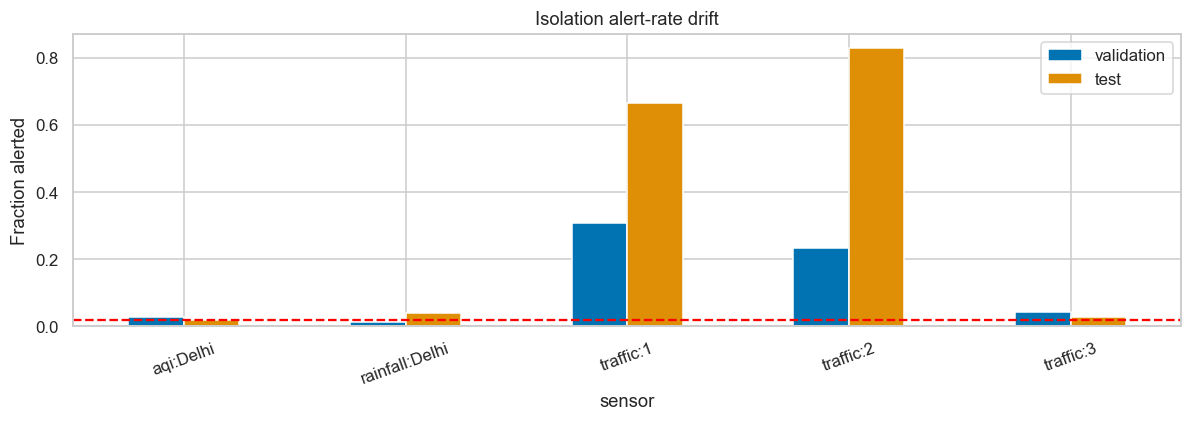

In [35]:
comparison=validation_rates[['isolation_alert']].rename(columns={'isolation_alert':'validation'}).join(final_rates[['isolation_alert']].rename(columns={'isolation_alert':'test'}))
display(comparison)
comparison.plot.bar(title='Isolation alert-rate drift',ylabel='Fraction alerted',rot=20);plt.axhline(.02,color='red',ls='--');plt.tight_layout();plt.show()

### 9.3 Alert stability across months

Independent source timelines are displayed in separate panels.

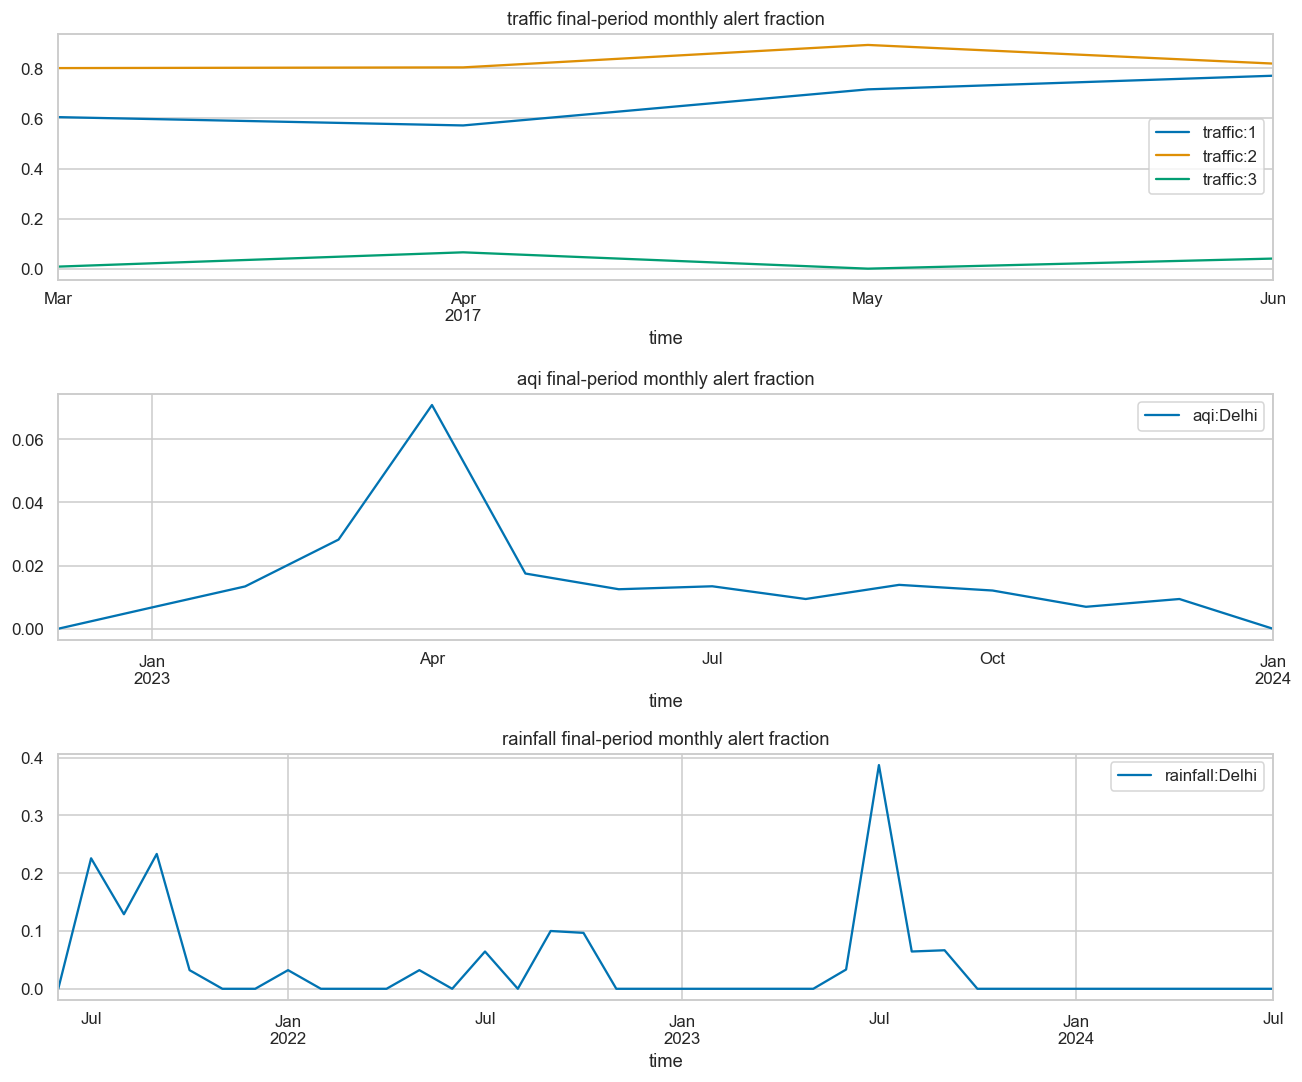

In [36]:
fig,axes=plt.subplots(3,1,figsize=(12,10))
monthly=[]
for family,ax in zip(['traffic','aqi','rainfall'],axes):
    for sensor,g in test_scores[test_scores.sensor.str.startswith(family+':')].groupby('sensor'):
        q=g.set_index('time').isolation_alert.resample('MS').mean()
        q.plot(ax=ax,label=sensor);monthly.extend({'sensor':sensor,'month':str(t),'alert_rate':v} for t,v in q.items())
    ax.set_title(family+' final-period monthly alert fraction');ax.legend()
plt.tight_layout();plt.show()
pd.DataFrame(monthly).to_csv(OUT/'monthly_alert_rates.csv',index=False)

### 9.4 Score distribution drift

These are descriptive empirical quantiles, not calibrated probabilities or exchangeable confidence intervals.

,sensor,period,quantile,score
0,aqi:Delhi,train,0.01,0.421385
1,aqi:Delhi,train,0.10,0.433215
2,aqi:Delhi,train,0.50,0.460036
3,aqi:Delhi,train,0.90,0.511314
4,aqi:Delhi,train,0.95,0.529715
5,aqi:Delhi,train,0.99,0.564183
6,aqi:Delhi,validation,0.01,0.420627
7,aqi:Delhi,validation,0.10,0.432876
8,aqi:Delhi,validation,0.50,0.460703
9,aqi:Delhi,validation,0.90,0.513504


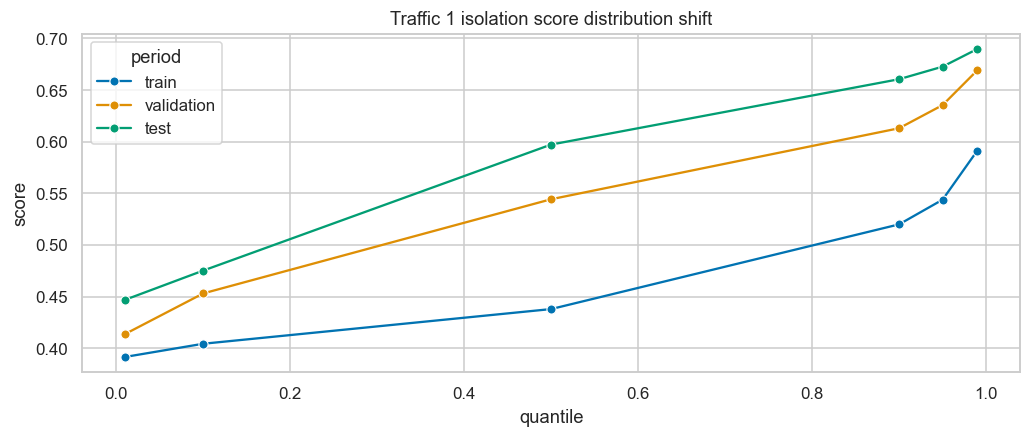

In [37]:
score_rows=[]
for sensor,model in suites.items():
    for split,values in [('train',model.train_scores_),('validation',val_scores[val_scores.sensor.eq(sensor)].isolation_score),('test',test_scores[test_scores.sensor.eq(sensor)].isolation_score)]:
        for q in [.01,.1,.5,.9,.95,.99]:score_rows.append({'sensor':sensor,'period':split,'quantile':q,'score':float(np.quantile(values,q))})
score_distribution=pd.DataFrame(score_rows)
display(score_distribution.head(18))
score_distribution.to_csv(OUT/'score_distributions.csv',index=False)
sns.lineplot(data=score_distribution[score_distribution.sensor.eq('traffic:1')],x='quantile',y='score',hue='period',marker='o')
plt.title('Traffic 1 isolation score distribution shift');plt.show()

### 9.5 Agreement among detectors

Agreement is not corroboration from an independent physical source: all three methods use the same underlying measurements.

,sensor,pair,jaccard,disagreement
0,aqi:Delhi,rule_alert / robust_alert,0.000000,0.009812
1,aqi:Delhi,rule_alert / isolation_alert,0.203980,0.018254
2,aqi:Delhi,robust_alert / isolation_alert,0.000000,0.017798
3,rainfall:Delhi,rule_alert / robust_alert,0.065789,0.249342
4,rainfall:Delhi,rule_alert / isolation_alert,0.091371,0.157155
5,rainfall:Delhi,robust_alert / isolation_alert,0.189349,0.120281
6,traffic:1,rule_alert / robust_alert,0.001965,0.348064
7,traffic:1,rule_alert / isolation_alert,0.502535,0.336074
8,traffic:1,robust_alert / isolation_alert,0.001028,0.665639
9,traffic:2,rule_alert / robust_alert,0.003413,0.500171


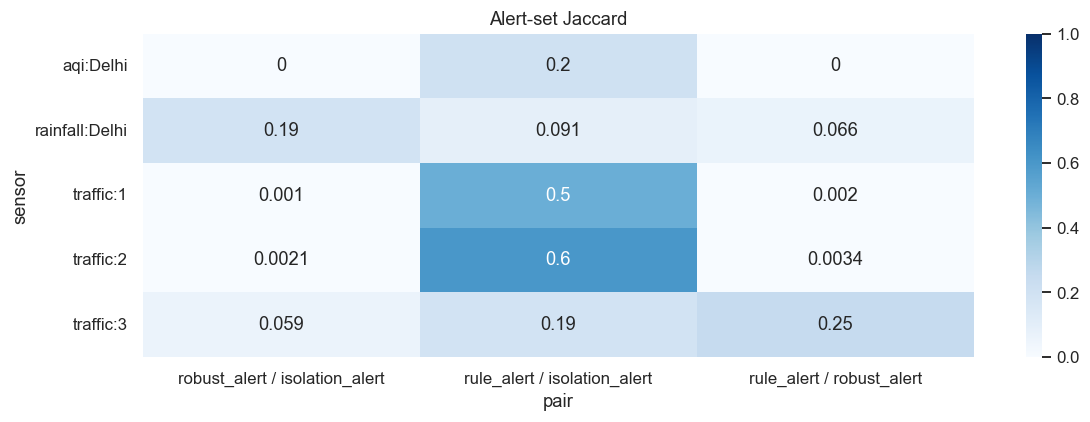

In [38]:
agreement=[]
for sensor,g in test_scores.groupby('sensor'):
    for a,b in [('rule_alert','robust_alert'),('rule_alert','isolation_alert'),('robust_alert','isolation_alert')]:
        aa=g[a].to_numpy();bb=g[b].to_numpy()
        agreement.append({'sensor':sensor,'pair':a+' / '+b,'jaccard':np.sum(aa&bb)/max(1,np.sum(aa|bb)),'disagreement':np.mean(aa!=bb)})
agreement=pd.DataFrame(agreement);display(agreement)
sns.heatmap(agreement.pivot(index='sensor',columns='pair',values='jaccard'),annot=True,vmin=0,vmax=1,cmap='Blues');plt.title('Alert-set Jaccard');plt.tight_layout();plt.show()
agreement.to_csv(OUT/'detector_agreement.csv',index=False)

### 9.6 Seasonal alert sensitivity on later data

Rainfall spikes may be legitimate monsoon observations. Detection does not distinguish environmental events from reporting faults.

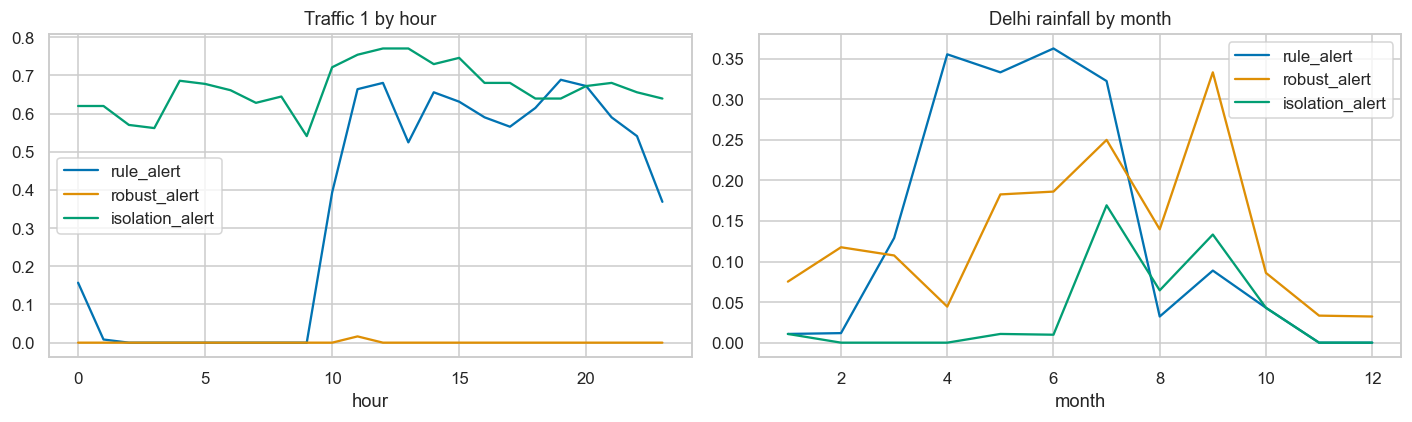

In [39]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
hourly=test_scores[test_scores.sensor.eq('traffic:1')].copy();hourly['hour']=hourly.time.dt.hour
hourly.groupby('hour')[['rule_alert','robust_alert','isolation_alert']].mean().plot(ax=ax[0],title='Traffic 1 by hour')
rain=test_scores[test_scores.sensor.eq('rainfall:Delhi')].copy();rain['month']=rain.time.dt.month
rain.groupby('month')[['rule_alert','robust_alert','isolation_alert']].mean().plot(ax=ax[1],title='Delhi rainfall by month')
plt.tight_layout();plt.show()

## 10. Isolated injected-anomaly robustness experiments

Eight documented perturbations are applied to **copies**: missing readings, one-point spike (+10 prior-context SD), persistent shift (+5 SD), gradual drift (0→6 SD), positive flatline, altered seasonal amplitude (3 SD sinusoid), negative invalid values and deleted intervals. The original source is never changed. Mechanisms and onset positions are selected without detector scores.

Each test fixture uses a bounded trailing context (1,200 hourly or 500 daily observations) wholly in the final period, with two onset seeds. Models stay frozen. Baselines are recomputed causally on the paired clean and perturbed context; this intentionally tests bounded-context behavior, not equality to the full-history service. Daily sinusoidal perturbations have a 24-day period, hourly ones 24 hours. Persistent-shift adaptation may suppress later detection.

Recovery = fraction of injected points alerted. Event detection = any alert within the injection interval. Delay is cadence steps to first alert. Unmodified-background alert fraction is **not a false-positive rate**, because untouched historical records have no known health labels. The seasonal-shift fixture is a distribution-change stress test, not a simulated equipment fault. No performance on these designed fixtures is promoted to real-world accuracy.

### 10.1 Injection manifest and paired evaluation

Evaluate three independent streams, eight mechanisms and two onset seeds. Report all mechanisms including poor recovery.

In [40]:
mechanisms=['missing','spike','persistent_shift','drift','flatline','seasonal_shift','invalid','data_gap']
fixture_results=[];manifests=[];case_fixtures={}
for sensor in ['traffic:1','aqi:Delhi','rainfall:Delhi']:
    spec=specs[sensor];model=suites[sensor]
    final_history=histories[sensor][histories[sensor].time>=pd.Timestamp(boundaries[spec.family]['test_start'])]
    context=final_history.tail(500 if spec.cadence=='D' else 1200).reset_index(drop=True)
    clean_f=causal_features(context,spec)
    clean_s=model.score(clean_f)
    for mechanism in mechanisms:
        for seed in [42,73]:
            injected,manifest=inject_fixture(context,spec,mechanism,seed)
            f=causal_features(injected,spec);scores=model.score(f)
            mask=injected.injected.to_numpy();eligible=f.ready.to_numpy()
            assert eligible[mask].all()
            manifest.update(sensor=sensor,context_rows=len(context),context_start=str(context.time.min()))
            manifests.append(manifest)
            for method in ['rule','robust','isolation','review']:
                alert=scores[method+'_alert'].to_numpy()
                baseline=clean_s[method+'_alert'].to_numpy()
                positions=np.flatnonzero(mask&alert)
                first=np.flatnonzero(mask)[0]
                fixture_results.append({'sensor':sensor,'mechanism':mechanism,'seed':seed,'detector':method,
                    'injected_points':int(mask.sum()),'recovery':float(alert[mask].mean()),
                    'matched_clean_alert_rate':float(baseline[mask].mean()),
                    'new_alert_fraction':float((alert[mask]&~baseline[mask]).mean()),
                    'background_alert_fraction':float(alert[eligible&~mask].mean()),
                    'event_detected':bool(len(positions)),
                    'delay_steps':float(positions[0]-first) if len(positions) else np.nan})
            if sensor=='traffic:1' and seed==42:case_fixtures[mechanism]=(injected,scores,manifest)
fixture_results=pd.DataFrame(fixture_results)
fixture_results.to_csv(OUT/'injected_recovery.csv',index=False)
(OUT/'injection_manifests.json').write_text(json.dumps(manifests,indent=2))
display(fixture_results.head(12))
print('Independent fixture copies',len(manifests),'method evaluations',len(fixture_results))

,sensor,mechanism,seed,detector,injected_points,recovery,matched_clean_alert_rate,new_alert_fraction,background_alert_fraction,event_detected,delay_steps
0,traffic:1,missing,42,rule,24,1.0,0.583333,0.416667,0.417535,True,0.0
1,traffic:1,missing,42,robust,24,0.0,0.041667,0.000000,0.001736,False,NaN
2,traffic:1,missing,42,isolation,24,0.0,0.958333,0.000000,0.758681,False,NaN
3,traffic:1,missing,42,review,24,1.0,0.958333,0.041667,0.758681,True,0.0
4,traffic:1,missing,73,rule,24,1.0,0.083333,0.916667,0.427951,True,0.0
5,traffic:1,missing,73,robust,24,0.0,0.000000,0.000000,0.001736,False,NaN
6,traffic:1,missing,73,isolation,24,0.0,0.083333,0.000000,0.776910,False,NaN
7,traffic:1,missing,73,review,24,1.0,0.083333,0.916667,0.776910,True,0.0
8,traffic:1,spike,42,rule,1,1.0,0.000000,1.000000,0.421277,True,0.0
9,traffic:1,spike,42,robust,1,1.0,0.000000,1.000000,0.001702,True,0.0


Independent fixture copies 48 method evaluations 192


### 10.2 Which detector responds to which mechanism?

Quality checks can recover missing/invalid points that Isolation Forest, trained on mostly complete data, may miss. Inspect the combined review signal separately.

detector,isolation,review,robust,rule
mechanism,,,,
data_gap,0.000000,1.000000,0.000000,1.000000
drift,0.672619,0.672619,0.361111,0.494048
flatline,0.451389,0.652778,0.000000,0.555556
invalid,0.000000,1.000000,0.000000,1.000000
missing,0.000000,1.000000,0.000000,1.000000
persistent_shift,1.000000,1.000000,0.437500,0.868056
seasonal_shift,0.637511,0.637511,0.066601,0.235064
spike,1.000000,1.000000,1.000000,1.000000


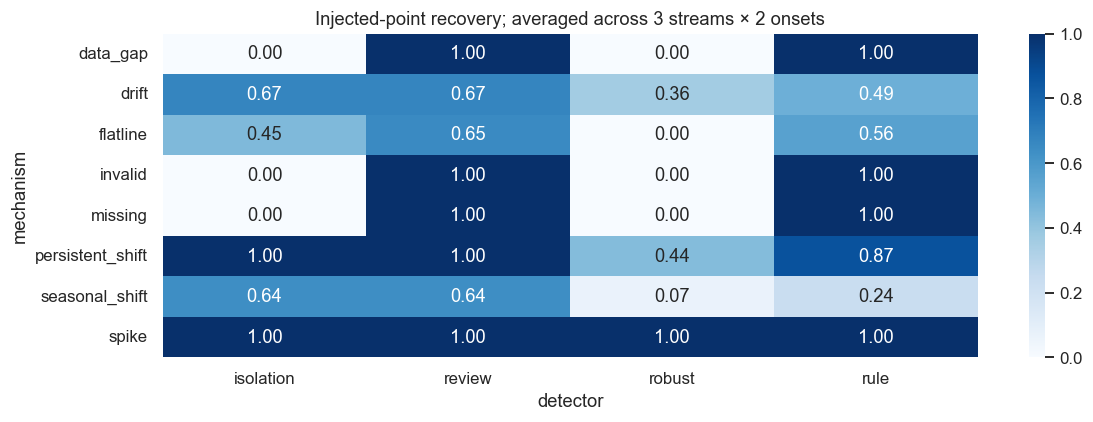

In [41]:
recovery=fixture_results.groupby(['mechanism','detector']).recovery.mean().unstack()
display(recovery)
sns.heatmap(recovery,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues');plt.title('Injected-point recovery; averaged across 3 streams × 2 onsets');plt.tight_layout();plt.show()

### 10.3 Stream-specific recovery

An identical mechanism can behave differently under daily zero-inflated rain and hourly traffic or pollutant distributions.

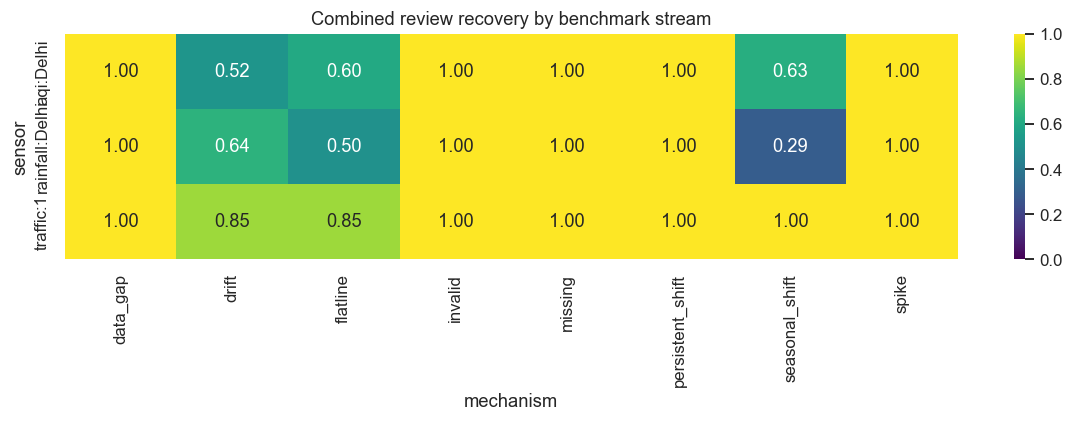

In [42]:
by_stream=fixture_results[fixture_results.detector.eq('review')].groupby(['sensor','mechanism']).recovery.mean().unstack()
sns.heatmap(by_stream,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='viridis');plt.title('Combined review recovery by benchmark stream');plt.tight_layout();plt.show()

### 10.4 Event detection, delays and background burden

A detector that alerts continuously would recover every injection but provide poor review value. Paired clean alerts and background burden reveal this weakness without pretending they are fault precision.

In [43]:
fixture_summary=fixture_results.groupby(['mechanism','detector']).agg(recovery=('recovery','mean'),event_detection=('event_detected','mean'),median_delay=('delay_steps','median'),matched_clean_alert=('matched_clean_alert_rate','mean'),new_alert_fraction=('new_alert_fraction','mean'),background_alert=('background_alert_fraction','mean'))
display(fixture_summary)
fixture_summary.to_csv(OUT/'injected_summary.csv')

recovery  event_detection  median_delay  \
mechanism        detector                                             
data_gap         isolation  0.000000         0.000000           NaN   
                 review     1.000000         1.000000           0.0   
                 robust     0.000000         0.000000           NaN   
                 rule       1.000000         1.000000           0.0   
drift            isolation  0.672619         1.000000           3.0   
                 review     0.672619         1.000000           3.0   
                 robust     0.361111         0.500000           0.0   
                 rule       0.494048         1.000000           5.0   
flatline         isolation  0.451389         0.666667           7.0   
                 review     0.652778         1.000000           5.0   
                 robust     0.000000         0.000000           NaN   
                 rule       0.555556         1.000000          10.0   
invalid          isolation  0.000000         0.000000           NaN   
                 review     1.000000         1.000000           0.0   
                 robust     0.000000         0.000000           NaN   
                 rule       1.000000         1.000000           0.0   
missing          isolation  0.000000         0.000000           NaN   
                 review     1.000000         1.000000           0.0   
                 robust     0.000000         0.000000           NaN   
                 rule       1.000000         1.000000           0.0   
persistent_shift isolation  1.000000         1.000000           0.0   
                 review     1.000000         1.000000           0.0   
                 robust     0.437500         0.833333           0.0   
                 rule       0.868056         1.000000           0.0   
seasonal_shift   isolation  0.637511         1.000000           3.0   
                 review     0.637511         1.000000           3.0   
                 robust     0.066601         0.500000           0.0   
                 rule       0.235064         0.833333           2.0   
spike            isolation  1.000000         1.000000           0.0   
                 review     1.000000         1.000000           0.0   
                 robust     1.000000         1.000000           0.0   
                 rule       1.000000         1.000000           0.0   

                            matched_clean_alert  new_alert_fraction  \
mechanism        detector                                             
data_gap         isolation             0.211310            0.000000   
                 review                0.211310            0.788690   
                 robust                0.173611            0.000000   
                 rule                  0.158730            0.841270   
drift            isolation             0.211310            0.461310   
                 review                0.211310            0.461310   
                 robust                0.173611            0.187500   
                 rule                  0.158730            0.359127   
flatline         isolation             0.211310            0.263889   
                 review                0.211310            0.465278   
                 robust                0.173611            0.000000   
                 rule                  0.158730            0.506944   
invalid          isolation             0.211310            0.000000   
                 review                0.211310            0.788690   
                 robust                0.173611            0.000000   
                 rule                  0.158730            0.841270   
missing          isolation             0.211310            0.000000   
                 review                0.211310            0.788690   
                 robust                0.173611            0.000000   
                 rule                  0.158730            0.841270   
persistent_shift isolation             0.211310    

### 10.5 Visual stress cases

Shading marks injected points only. Red markers are the quality-or-isolation review signal.

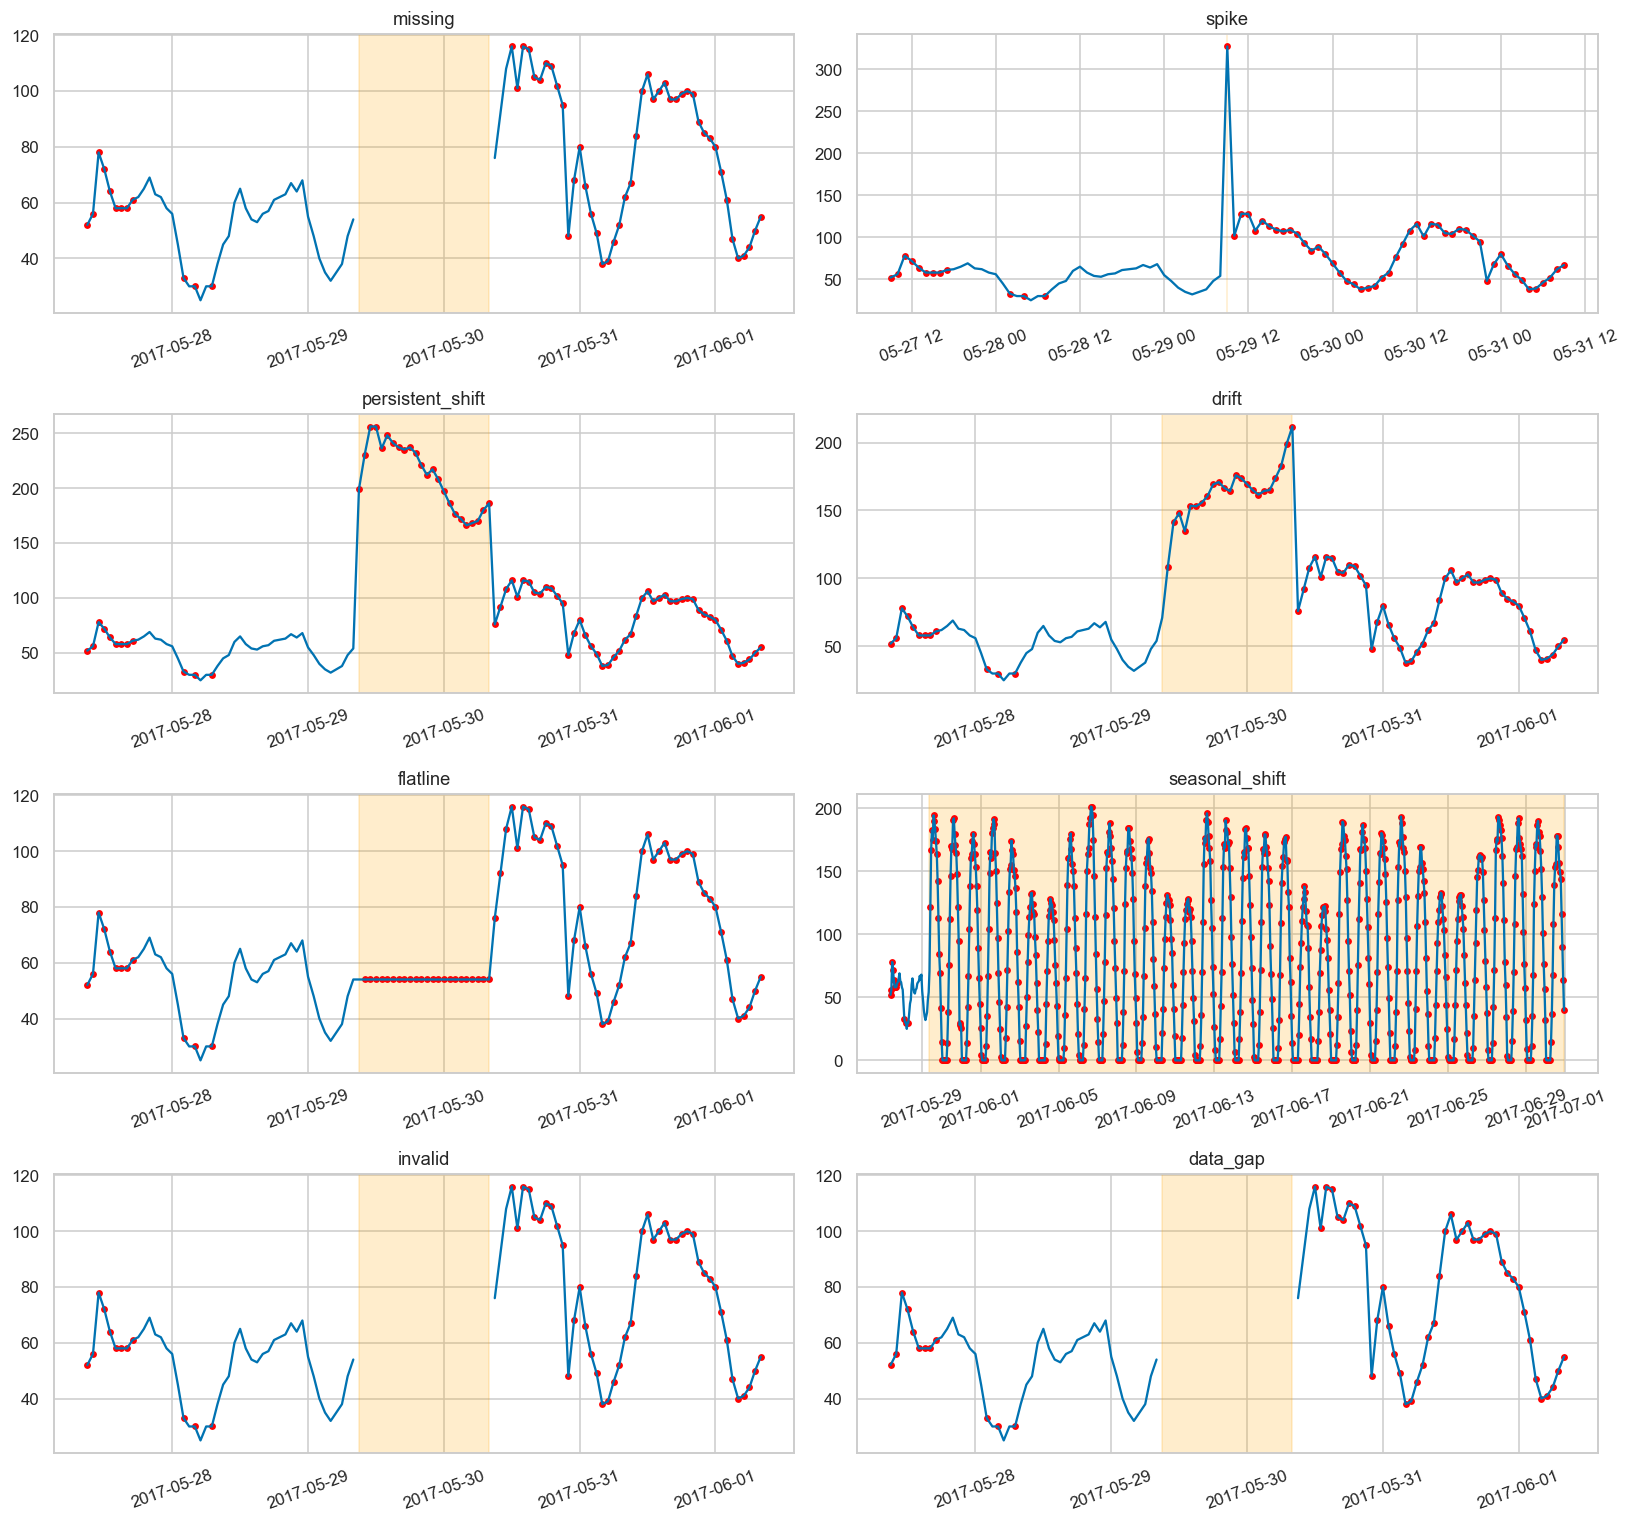

In [44]:
fig,axes=plt.subplots(4,2,figsize=(15,14))
for mechanism,ax in zip(mechanisms,axes.flat):
    h,s,manifest=case_fixtures[mechanism];loc=np.flatnonzero(h.injected)
    a=max(0,loc[0]-48);b=min(len(h),loc[-1]+49)
    z=h.iloc[a:b];q=s.iloc[a:b]
    ax.plot(z.time,z.value,label='Perturbed measurement')
    ax.axvspan(h.iloc[loc[0]].time,h.iloc[loc[-1]].time,alpha=.2,color='orange')
    mask=q.review_alert.to_numpy();ax.scatter(z.time[mask],z.value[mask],c='red',s=12)
    ax.set_title(mechanism);ax.tick_params(axis='x',rotation=20)
plt.tight_layout();plt.show()

### 10.6 Unknown identity and cold-start handling

Anomaly evidence cannot be transferred from a known junction into an unseen identity. Natural late-appearing Junction 4 supplies this test.

In [45]:
service=AnomalyService(suites,specs)
unknown='traffic:4'
unknown_payload=service.predict(unknown,histories[unknown],histories[unknown].time.max())
print(json.dumps(unknown_payload,indent=2))
assert unknown_payload['alert'] is None and unknown_payload['supported_sensor'] is False

{
  "component": "infrastructure_measurement_anomaly",
  "version": "1.0.0",
  "sensor": "traffic:4",
  "supported_sensor": false,
  "observation_time": "2017-06-30 23:00:00",
  "detection_time": "2026-10-25T12:48:35.112127+00:00",
  "horizon": "contemporaneous detection",
  "anomaly_score": null,
  "threshold": null,
  "alert": null,
  "detector_type": "IsolationForest + independent quality rules",
  "contributing_indicators": [],
  "input_freshness": {
    "status": "unassessed",
    "age_hours": null
  },
  "provenance": "observational benchmark; city, coordinates and timezone not supplied",
  "input_sources": [
    "https://www.kaggle.com/datasets/fedesoriano/traffic-prediction-dataset"
  ],
  "entity": "4",
  "geographic_scope": "unmapped benchmark entity",
  "units": "vehicles/hour",
  "observation_timezone": null,
  "research_only": true,
  "synthetic": false,
  "validation_status": "historical benchmark + injected-fixture testing only",
  "confirmed_failure": false,
  "dispatch

## 11. Explainability and case studies

Rule outputs identify the violated checks. For Isolation Forest we show train-relative features and controlled score sensitivity: replace one feature by its training median, holding others fixed, and observe the score change. This is a diagnostic of model behavior, not causal attribution, a probability contribution, or a proof of sensor failure. Correlated rolling features can make these counterfactual combinations unrealistic.

### 11.1 Inspect high-scoring real records

These are unusual historical measurements with unknown fault status. Keep the original units and source identity.

In [46]:
cases=test_scores.sort_values('isolation_score',ascending=False).groupby('sensor',sort=False).head(2)
display(cases[['sensor','time','value','isolation_score','isolation_alert','quality_alert','violated_rules']])
cases.to_csv(OUT/'historical_case_studies.csv',index=False)

,sensor,time,value,isolation_score,isolation_alert,quality_alert,violated_rules
9242,rainfall:Delhi,2022-10-09 00:00:00,67.460000,0.769635,True,False,"above_train_p995,abrupt_change"
9516,rainfall:Delhi,2023-07-10 00:00:00,50.660000,0.757132,True,False,above_train_p995
15302,traffic:2,2017-06-12 16:00:00,40.000000,0.749994,True,False,above_train_p995
15303,traffic:2,2017-06-12 17:00:00,38.000000,0.732269,True,False,above_train_p995
18460,traffic:3,2017-06-22 15:00:00,83.000000,0.706707,True,False,"above_train_p995,abrupt_change"
11946,traffic:1,2017-05-25 11:00:00,128.000000,0.704564,True,False,"above_train_p995,abrupt_change"
11901,traffic:1,2017-05-23 14:00:00,113.000000,0.702519,True,False,above_train_p995
16520,traffic:3,2017-04-02 19:00:00,67.000000,0.700366,True,False,"above_train_p995,abrupt_change"
2534,aqi:Delhi,2023-04-16 10:00:00,138.006596,0.627710,True,False,above_train_p995
2526,aqi:Delhi,2023-04-16 02:00:00,128.296723,0.617444,True,False,above_train_p995


### 11.2 Expose violated rules

Missingness, invalidity, sudden change and training-quantile exceedance are transparent observations, not municipal fault codes.

,sensor,time,value,violated_rules
397,aqi:Delhi,2023-01-17 09:00:00,108.930343,abrupt_change
562,aqi:Delhi,2023-01-24 06:00:00,92.354112,abrupt_change
1012,aqi:Delhi,2023-02-12 00:00:00,126.023261,"above_train_p995,abrupt_change"
8767,rainfall:Delhi,2021-06-21 00:00:00,NaN,missing_reading
8769,rainfall:Delhi,2021-06-23 00:00:00,NaN,missing_reading
8770,rainfall:Delhi,2021-06-24 00:00:00,NaN,missing_reading
9906,traffic:1,2017-03-01 11:00:00,84.000000,above_train_p995
9907,traffic:1,2017-03-01 12:00:00,87.000000,above_train_p995
9909,traffic:1,2017-03-01 14:00:00,82.000000,above_train_p995
12823,traffic:2,2017-03-01 09:00:00,26.000000,"above_train_p995,abrupt_change"


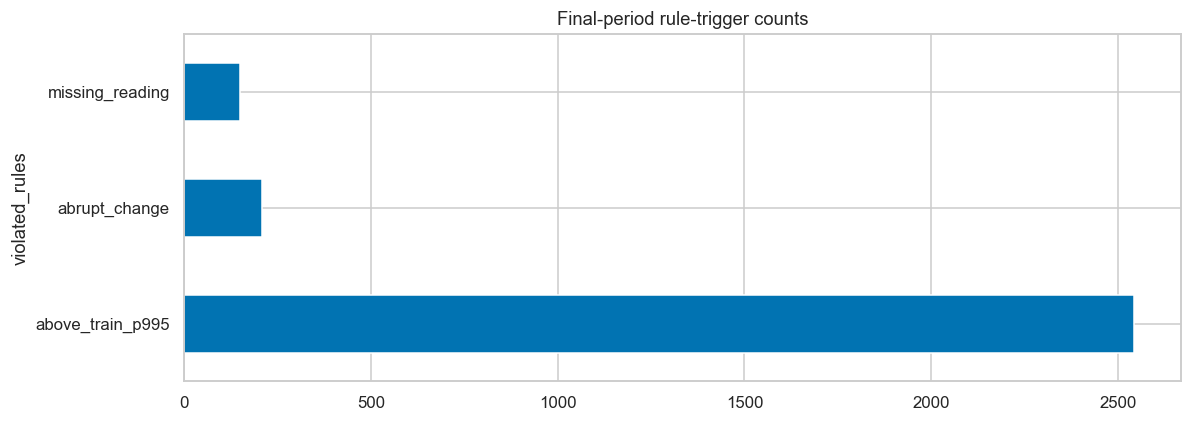

In [47]:
rule_cases=test_scores[test_scores.rule_alert].groupby('sensor').head(3)
display(rule_cases[['sensor','time','value','violated_rules']])
rule_counts=test_scores.violated_rules.str.split(',').explode().value_counts()
rule_counts=rule_counts[rule_counts.index!='']
rule_counts.plot.barh(title='Final-period rule-trigger counts');plt.tight_layout();plt.show()

### 11.3 Model-score sensitivity for one traffic case

A positive score drop means replacing that feature by its train median reduced anomaly score; it does not identify the physical cause.

,sensor,time,value,rolling_mean,rolling_std,rolling_median,rolling_mad,rolling_min,rolling_max,robust_z,...,seasonal_residual,baseline_deviation,missing,invalid,missing_fraction,flat_run,previous_unusual_count,hours_since_valid,hour_sin,hour_cos
63231,traffic:1,2017-05-25 11:00:00,128.0,80.875,24.930011,90.0,18.0,38.0,111.0,1.423925,...,67.333333,3.944202,0,0,0.0,1,0.0,0.0,0.258819,-0.965926


,feature,value,training_median,score_drop_on_median_replacement
0,value,128.000000,3.100000e+01,0.023003
1,seasonal_residual,67.333333,6.666667e+00,0.022328
2,rolling_max,111.000000,4.700000e+01,0.022277
3,baseline_deviation,3.944202,5.351699e-01,0.020756
4,rolling_std,24.930011,9.257097e+00,0.019320
5,rate_change,37.000000,0.000000e+00,0.016738
6,rolling_min,38.000000,1.600000e+01,0.014973
7,rolling_mad,18.000000,6.000000e+00,0.014654
8,rolling_median,90.000000,3.500000e+01,0.007500
9,hour_cos,-0.965926,-1.836970e-16,0.007220


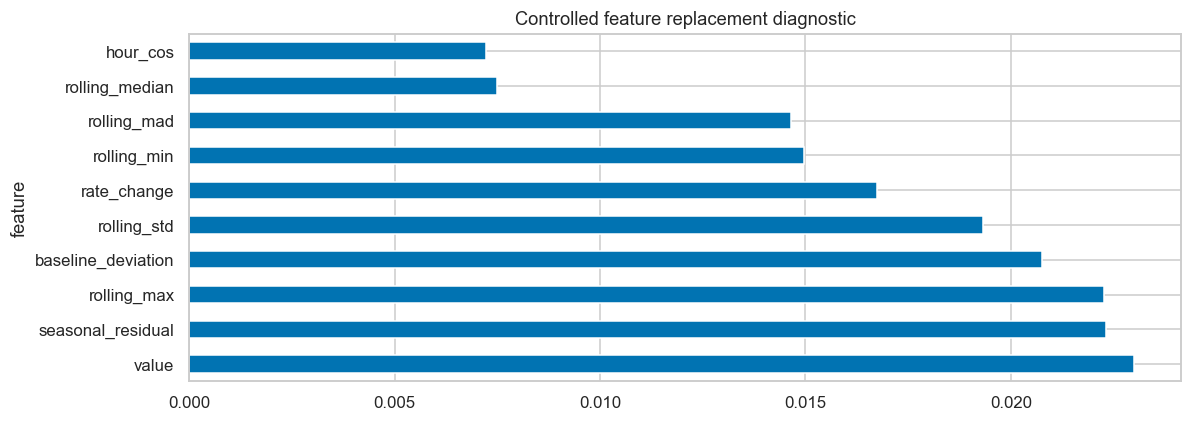

In [48]:
case=test_scores[test_scores.sensor.eq('traffic:1')].nlargest(1,'isolation_score').iloc[0]
row=test[test.sensor.eq(case.sensor)&test.time.eq(case.time)]
diagnostic=pd.DataFrame(suites[case.sensor].diagnose(row,top=10))
display(row[['sensor','time']+FEATURES]);display(diagnostic)
diagnostic.plot.barh(x='feature',y='score_drop_on_median_replacement',legend=False,title='Controlled feature replacement diagnostic');plt.tight_layout();plt.show()
diagnostic.to_csv(OUT/'case_feature_diagnostics.csv',index=False)

### 11.4 Train-relative case context

Display the historical case against the preceding week. Nearby values can be useful corroborating context, but they are not independent device-health measurements.

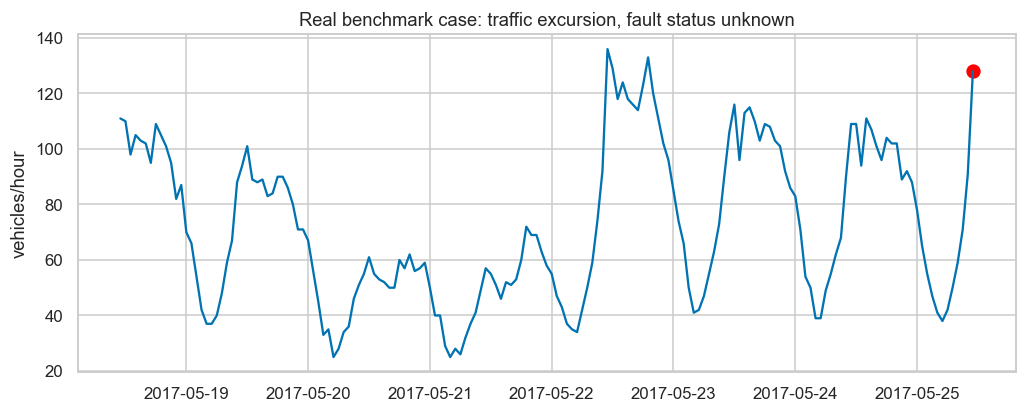

In [49]:
h=histories[case.sensor];context=h[(h.time>=case.time-pd.Timedelta(days=7))&(h.time<=case.time)]
plt.plot(context.time,context.value);plt.scatter([case.time],[case.value],c='red',s=70)
plt.title('Real benchmark case: traffic excursion, fault status unknown');plt.ylabel(specs[case.sensor].unit);plt.show()

### 11.5 Inspect a missed injected event

Poor recovery is retained and explained as a limitation. Imputation, adaptive baselines and a sparse training distribution can all limit detection.

In [50]:
weak=fixture_results.sort_values(['recovery','new_alert_fraction']).head(12)
display(weak[['sensor','mechanism','seed','detector','recovery','event_detected','delay_steps','matched_clean_alert_rate']])
print('These are designed test interventions. Their missed recovery does not estimate missed real municipal failures.')

,sensor,mechanism,seed,detector,recovery,event_detected,delay_steps,matched_clean_alert_rate
1,traffic:1,missing,42,robust,0.0,False,NaN,0.041667
2,traffic:1,missing,42,isolation,0.0,False,NaN,0.958333
5,traffic:1,missing,73,robust,0.0,False,NaN,0.000000
6,traffic:1,missing,73,isolation,0.0,False,NaN,0.083333
29,traffic:1,drift,73,robust,0.0,False,NaN,0.000000
33,traffic:1,flatline,42,robust,0.0,False,NaN,0.041667
37,traffic:1,flatline,73,robust,0.0,False,NaN,0.000000
45,traffic:1,seasonal_shift,73,robust,0.0,False,NaN,0.000000
49,traffic:1,invalid,42,robust,0.0,False,NaN,0.041667
50,traffic:1,invalid,42,isolation,0.0,False,NaN,0.958333


These are designed test interventions. Their missed recovery does not estimate missed real municipal failures.


## 12. Reusable inference, versioned export and tests

Inference accepts one source-qualified sensor, its causal history, an expected observation timestamp and an aware detection timestamp. Input time remains on the documented source wall clock. For Asia/Kolkata assumptions, UTC age is computed explicitly; traffic’s unknown timezone produces freshness=unknown. Missing tail slots are materialized, and last-valid-reading age is reported. Unknown/untrained identities and insufficient history abstain. Scoring at/before training cutoff is rejected.

The service requires full preceding history to reproduce expanding-baseline values; bounded context is a separately documented approximation used only in the fixture experiments. No online model refitting occurs. Fitted preprocessing and detectors are saved only after successful training and diagnostics. Copy `src/` and `civicflux_core.py` with the joblib; load only trusted artifacts.

### 12.1 Versioned configuration and model card

The model card records source hashes, fit cutoffs, numerical feature floors, unverified provenance and blocked real-fault evaluation.

In [51]:
model_card={'component':'infrastructure_measurement_anomaly','version':VERSION,'research_only':True,
 'objective':'flag unusual measurements; never confirm asset failure','source_inventory':inventory.to_dict('records'),
 'supported_sensors':sorted(suites),'untrained_sensors':sorted(set(specs)-set(suites)),
 'sensor_specs':{k:asdict(v) for k,v in specs.items()},'fit_summary':fit_rows,'config':locked,
 'labels':'No verified equipment-fault labels; injection support labels only',
 'real_data_metrics':'alert rates, score distributions, temporal stability; no fault precision or accuracy',
 'fixture_metrics':'point recovery, event detection, delay and matched clean alert burden',
 'limitations':['No real water-level, pressure, flow or fault observations','No verified municipal asset mapping',
                'AQI unit/measurement provenance unverified','Traffic timezone unknown','Adaptive baselines can absorb persistent shifts',
                '2% contamination is an assumption, not fault prevalence','State rainfall is not a local drainage sensor'],
 'integration_status':'pure evidence adapter; CivicFlux backend schema unavailable','dispatch_allowed':False,
 'versions':{name:importlib.metadata.version(name) for name in ['numpy','pandas','scikit-learn','joblib']}}
(OUT/'model_card.json').write_text(json.dumps(model_card,indent=2,default=str))
joblib.dump(service,OUT/'detectors.joblib')
print('Saved actually fitted suites:',len(suites),'to',OUT)

Saved actually fitted suites: 5 to /Users/jiyahooda/Documents/New project/civicflux_ml/artifacts/infrastructure_anomaly/v1.0.0


### 12.2 Serialize/reload and inspect full output contract

Use a fixed detection instant for reproducibility. Because the file ends in the past, the input is correctly marked stale.

In [52]:
loaded=joblib.load(OUT/'detectors.joblib')
sensor='aqi:Delhi';h=histories[sensor];detected_at=pd.Timestamp('2026-10-25T00:00:00Z')
output=loaded.predict(sensor,h,h.time.max(),detected_at)
assert output==service.predict(sensor,h,h.time.max(),detected_at)
json.dumps(output,allow_nan=False)
print(json.dumps(output,indent=2))
(OUT/'inference_example.json').write_text(json.dumps(output,indent=2))
assert output['input_freshness']['status']=='stale' and output['confirmed_failure'] is False

{
  "component": "infrastructure_measurement_anomaly",
  "version": "1.0.0",
  "sensor": "aqi:Delhi",
  "supported_sensor": true,
  "observation_time": "2024-01-01 00:00:00",
  "detection_time": "2026-10-25T00:00:00+00:00",
  "horizon": "contemporaneous detection",
  "anomaly_score": 0.5192228814781328,
  "threshold": 0.551175517952252,
  "alert": false,
  "detector_type": "IsolationForest + independent quality rules",
  "contributing_indicators": [
    {
      "feature": "robust_z",
      "value": 2.6440771740810067,
      "training_median": -0.004630757078853778,
      "score_drop_on_median_replacement": 0.025804834027595702
    },
    {
      "feature": "seasonal_residual",
      "value": 33.18020013187358,
      "training_median": -6.675494140903567,
      "score_drop_on_median_replacement": 0.013057070186458741
    },
    {
      "feature": "rate_change",
      "value": 49.43353709688155,
      "training_median": 0.0,
      "score_drop_on_median_replacement": 0.011617909430112983


### 12.3 Quality and invalid-input contract example

The adapter must carry the quality warning even if the Isolation Forest score itself is below threshold.

In [53]:
copy=histories['traffic:1'].copy();copy.loc[copy.index[-1],'value']=np.nan
copy.attrs['synthetic_fixture']=True
quality_output=loaded.predict('traffic:1',copy,copy.time.max(),detected_at)
print(json.dumps({k:quality_output[k] for k in ['sensor','anomaly_score','isolation_alert','quality_alert','alert','input_freshness','synthetic','warnings']},indent=2))
assert quality_output['quality_alert'] and quality_output['alert']

{
  "sensor": "traffic:1",
  "anomaly_score": 0.5761468575862747,
  "isolation_alert": true,
  "quality_alert": true,
  "alert": true,
  "input_freshness": {
    "status": "unknown",
    "age_hours": null,
    "hours_since_valid_on_source_clock": 1.0
  },
  "synthetic": true,
  "warnings": [
    "Unusual measurements are not confirmed equipment failures.",
    "Injected test fixture, not an observed incident.",
    "Unknown source timezone: wall-clock freshness cannot be verified.",
    "Current value unavailable; numeric score uses train-fitted imputation and must be read with the quality flag."
  ]
}


### 12.4 Automated integrity and serving tests

Run both the legacy test suite and the new tests: missing/invalid/stale/constant/unknown inputs, reproducibility, reload, causality, rule thresholds and dispatch suppression.

In [54]:
result=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'tests'),'-v'],cwd=ROOT,text=True,capture_output=True)
print(result.stdout+result.stderr)
(OUT/'tests.txt').write_text(result.stdout+result.stderr)
assert result.returncode==0,'Automated integrity test failure'

test_adapter_blocks_dispatch_even_if_input_tampered (test_anomaly.AnomalyTests.test_adapter_blocks_dispatch_even_if_input_tampered) ... ok
test_constant_series (test_anomaly.AnomalyTests.test_constant_series) ... ok
test_current_excluded_from_reference (test_anomaly.AnomalyTests.test_current_excluded_from_reference) ... ok
test_dry_rain_not_flatline_fault (test_anomaly.AnomalyTests.test_dry_rain_not_flatline_fault) ... ok
test_duplicate_conflict (test_anomaly.AnomalyTests.test_duplicate_conflict) ... ok
test_fixture_does_not_mutate_input (test_anomaly.AnomalyTests.test_fixture_does_not_mutate_input) ... ok
test_future_feature_invariance (test_anomaly.AnomalyTests.test_future_feature_invariance) ... ok
test_future_observation_rejected (test_anomaly.AnomalyTests.test_future_observation_rejected) ... ok
test_gap_is_materialized (test_anomaly.AnomalyTests.test_gap_is_materialized) ... ok
test_insufficient_context_abstains (test_anomaly.AnomalyTests.test_insufficient_context_abstains) ... o

### 12.5 Preserve notebooks 01–04 and their artifacts

The initial checksums were captured before any changes. This confirms the extension did not regenerate or overwrite legacy outputs.

In [55]:
preserved=json.loads((ROOT/'reports/notebook05/preserved_before.json').read_text())
changed=[name for name,digest in preserved.items() if not (ROOT/name).exists() or sha256(ROOT/name)!=digest]
assert not changed,changed
print('PASS:',len(preserved),'existing notebook/artifact files unchanged byte-for-byte')
(OUT/'preservation_check.json').write_text(json.dumps({'checked_files':len(preserved),'changed':changed},indent=2))

PASS: 60 existing notebook/artifact files unchanged byte-for-byte


42

## 13. CivicFlux evidence integration and findings

The inspected CivicFlux workspace contains research bundles/payloads but no actual infrastructure-risk API, graph/optimizer or municipal asset registry. Therefore the integration is a **thin pure-function evidence adapter**, not a fabricated live backend connection. No unrelated FastAPI schema is modified. A future backend must establish verified asset mapping and preserve its own corroboration/approval rules.

The evidence envelope contains the version, source-qualified entity, input sources, observation/detection times, units, anomaly score/threshold, contributing indicators, freshness, provenance and research status. `asset_id=null`, `requires_corroboration=true`, `confirmed_failure=false`, `eligible_for_operational_risk_fusion=false`, and `automatic_dispatch_allowed=false`. The adapter has no dispatch capability or side effect.

### 13.1 Thin evidence adapter

A downstream graph may store this as research evidence awaiting corroboration; it must not equate it with a guaranteed equipment-failure node.

In [56]:
evidence=evidence_adapter(output)
print(json.dumps(evidence,indent=2))
assert not evidence['automatic_dispatch_allowed'] and not evidence['confirmed_failure']
assert evidence['asset_id'] is None and evidence['requires_corroboration']
(OUT/'civicflux_evidence_example.json').write_text(json.dumps(evidence,indent=2))

{
  "contract_version": "civicflux.anomaly-evidence.v1",
  "evidence_type": "unusual_measurement",
  "entity": "aqi:Delhi",
  "asset_id": null,
  "requires_verified_asset_mapping": true,
  "measurement_evidence": {
    "component": "infrastructure_measurement_anomaly",
    "version": "1.0.0",
    "sensor": "aqi:Delhi",
    "supported_sensor": true,
    "observation_time": "2024-01-01 00:00:00",
    "detection_time": "2026-10-25T00:00:00+00:00",
    "horizon": "contemporaneous detection",
    "anomaly_score": 0.5192228814781328,
    "threshold": 0.551175517952252,
    "alert": false,
    "detector_type": "IsolationForest + independent quality rules",
    "contributing_indicators": [
      {
        "feature": "robust_z",
        "value": 2.6440771740810067,
        "training_median": -0.004630757078853778,
        "score_drop_on_median_replacement": 0.025804834027595702
      },
      {
        "feature": "seasonal_residual",
        "value": 33.18020013187358,
        "training_median"

3107

### 13.2 Actual measured findings

Generate conclusions from executed measurements; no predetermined success score is inserted.

In [57]:
print('Fitted sensor/entity suites:',len(suites))
print('Held-out scored rows:',len(test_scores),'Unsupported rows:',int(unsupported.sum()))
print('Isolation Forest later alert rates (%):')
print((100*final_rates.isolation_alert).round(2).to_string())
print('Injected point recovery, combined review (%):')
print((100*fixture_results[fixture_results.detector.eq('review')].groupby('mechanism').recovery.mean()).round(2).to_string())
findings={'fitted_suites':len(suites),'scored_test_rows':len(test_scores),'unsupported_test_rows':int(unsupported.sum()),
          'test_alert_rates':final_rates.to_dict('index'),
          'fixture_recovery':recovery.to_dict('index'),'fixture_copies':len(manifests),
          'real_fault_precision':None,'real_fault_accuracy':None,'dispatch_allowed':False}
(OUT/'findings.json').write_text(json.dumps(findings,indent=2))

Fitted sensor/entity suites: 5
Held-out scored rows: 18661 Unsupported rows: 2919
Isolation Forest later alert rates (%):
sensor
aqi:Delhi          1.78
rainfall:Delhi     4.04
traffic:1         66.63
traffic:2         83.01
traffic:3          2.81
Injected point recovery, combined review (%):
mechanism
data_gap            100.00
drift                67.26
flatline             65.28
invalid             100.00
missing             100.00
persistent_shift    100.00
seasonal_shift       63.75
spike               100.00


2460

### 13.3 Limitations, interpretation and next dependencies

Anomaly evidence is useful for review prioritization, but the present experiment cannot diagnose municipal equipment failure. The reported alert rates are not false-positive rates. Injected recovery depends on the designed amplitude, duration, context and onset seeds; two onsets and three streams are not a validated municipal incident population. Adaptive rolling/seasonal baselines can absorb drift and sustained shifts. A missing-value indicator may be unseen in development, so independent data-quality checks remain necessary. Rainfall zero spells are expected; city-level pollution does not localize a specific sensor fault.

Before live integration: supply the actual CivicFlux backend schemas and asset registry; provide verified sensor-to-asset mapping, measurement units, timestamp/receive-time semantics and telemetry freshness requirements; collect observed water/pressure/flow readings and adjudicated incidents; validate thresholds and costs using future/site holdouts; distinguish sensor faults from legitimate environmental events with independent corroboration. None of those absent datasets or interfaces is silently substituted here. Existing approval and resource-allocation workflows remain untouched.